# **KINDLY UPVOTE THE NOTEBOOK IF YOU FIND IT INSIGHTFUL**

#  ELECTRICITY DEMAND IN UNITED KINGDOM - "TIME SERIES ANALYSIS AND FORECASTING FOR YEAR-2024 WITH DEEP LEARNING MODELS"

# Objective:

       To analyze historical electricity demand data and apply time series forecasting methods to predict the electricity demand for NS, TSD, and England and Wales in 2024.

# DATASET INFO:

    National Grid ESO is the electricity system operator for Great Britain. They have gathered information of the electricity demand in Great Britain from 2009. The is updated twice an hour, which means 48 entries per day. This makes this dataset ideal for time series forecasting.

    * SETTLEMENT_PERIOD: half hourly period for the historic outtunr occurred

    * ND (National Demand). National Demand is the sum of metered generation, but excludes generation required to meet station load, pump storage pumping and interconnector exports. National Demand is calculated as a sum of generation based on National Grid ESO operational generation metering. Measured in MW.


    * TSD (Transmission System Demand). Transmission System Demand is equal to the ND plus the additional generation required to meet station load, pump storage pumping and interconnector exports. Measured in MW.


    * ENGLAND_WALES_DEMAND. England and Wales Demand, as ND above but on an England and Wales basis. Measured in MW.

# IMPORTING REQUIRED LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='darkgrid')
plt.style.use('bmh')
import datetime as dt

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
odf=pd.read_excel("C:/Users/Sethu/Downloads/da/uk electricity deman.xlsx",
                  sheet_name='historic_demand_2009_2023',parse_dates=[1],
                 )


In [4]:
odf.head()

,date,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_wind_capacity,embedded_solar_generation,embedded_solar_capacity,non_bm_stor,pump_storage_pumping,ifa_flow,ifa2_flow,britned_flow,moyle_flow,east_west_flow,nemo_flow,nsl_flow,eleclink_flow,is_holiday
0,2009-01-01,1,37910,38704,33939,54,1403,0,0,0,33,2002,0,0,-161,0,0,NaN,NaN,1
1,2009-01-01,2,38047,38964,34072,53,1403,0,0,0,157,2002,0,0,-160,0,0,NaN,NaN,1
2,2009-01-01,3,37380,38651,33615,53,1403,0,0,0,511,2002,0,0,-160,0,0,NaN,NaN,1
3,2009-01-01,4,36426,37775,32526,50,1403,0,0,0,589,1772,0,0,-160,0,0,NaN,NaN,1
4,2009-01-01,5,35687,37298,31877,50,1403,0,0,0,851,1753,0,0,-160,0,0,NaN,NaN,1


In [5]:
new_columns_name=['nd','tsd','ewd','em_wind_gen','em_wind_cap',
'em_solar_gen','em_solar_cap','non_balacing_mech_stor','pump_storage_pumping','is_holiday']
odf.isna().sum()

date                              0
settlement_period                 0
nd                                0
tsd                               0
england_wales_demand              0
embedded_wind_generation          0
embedded_wind_capacity            0
embedded_solar_generation         0
embedded_solar_capacity           0
non_bm_stor                       0
pump_storage_pumping              0
ifa_flow                          0
ifa2_flow                         0
britned_flow                      0
moyle_flow                        0
east_west_flow                    0
nemo_flow                         0
nsl_flow                     175296
eleclink_flow                175296
is_holiday                        0
dtype: int64

In [6]:
odf.columns

Index(['date', 'settlement_period', 'nd', 'tsd', 'england_wales_demand',
       'embedded_wind_generation', 'embedded_wind_capacity',
       'embedded_solar_generation', 'embedded_solar_capacity', 'non_bm_stor',
       'pump_storage_pumping', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'is_holiday'],
      dtype='object')

In [7]:
df=odf.groupby(['date'])['nd', 'tsd', 'england_wales_demand','embedded_wind_generation', 'embedded_wind_capacity',
       'embedded_solar_generation', 'embedded_solar_capacity', 'non_bm_stor',
       'pump_storage_pumping','is_holiday'].mean()

df.columns=new_columns_name
df.asfreq('D')
df.head()

,nd,tsd,ewd,em_wind_gen,em_wind_cap,em_solar_gen,em_solar_cap,non_balacing_mech_stor,pump_storage_pumping,is_holiday
date,,,,,,,,,,
2009-01-01,37277.520833,38528.395833,33527.729167,65.666667,1403.0,0.0,0.0,0.000000,539.854167,1.0
2009-01-02,40015.020833,41133.458333,36087.083333,292.395833,1403.0,0.0,0.0,5.354167,391.500000,0.0
2009-01-03,39535.229167,40667.791667,35530.187500,185.375000,1403.0,0.0,0.0,3.145833,441.958333,0.0
2009-01-04,39820.979167,41013.958333,35889.770833,330.354167,1403.0,0.0,0.0,4.625000,474.104167,0.0
2009-01-05,45450.958333,47322.312500,41006.854167,508.916667,1403.0,0.0,0.0,10.125000,554.875000,0.0


     As the datset was collected from the year 2009 to 2023. I would like to take the data from 2018 to 2023 ending from November month and  try to do time series analysis models to forecast the electricity demand for Uk for the future year 2024. 

In [8]:
df=df['2018-01-01':][['nd','tsd','ewd']]
df

,nd,tsd,ewd
date,,,
2018-01-01,29072.041667,30282.333333,26426.250000
2018-01-02,34863.416667,36009.041667,32155.645833
2018-01-03,34499.708333,35690.979167,31515.562500
2018-01-04,36414.145833,37628.979167,32892.625000
2018-01-05,36975.916667,38260.333333,33564.145833
...,...,...,...
2023-11-26,30793.270833,32339.250000,27971.500000
2023-11-27,32639.500000,34158.270833,29881.958333
2023-11-28,33215.854167,34933.375000,30112.979167


In [9]:
des=df.describe().T.reset_index()
des

,index,count,mean,std,min,25%,50%,75%,max
0,nd,2160.0,27940.401148,4477.192068,17560.187500,24508.348958,27523.072917,31172.145833,40297.229167
1,tsd,2160.0,29562.634483,4396.379498,19465.666667,26365.114375,29070.510417,32605.197917,42152.291667
2,ewd,2160.0,25536.004559,4118.764655,16450.625000,22362.067708,25094.395833,28611.796875,37573.791667


<Axes: title={'center': 'Electricity Demand'}, xlabel='date', ylabel='MW'>

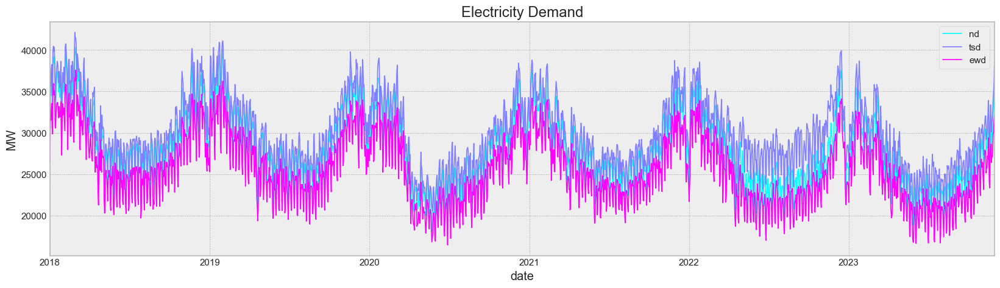

In [10]:
df.plot(figsize=(20,5),linewidth=1.2,cmap='cool',ylabel='MW',title='Electricity Demand')

# DATA PREPROCESSING

In [11]:
import tensorflow as tf
import keras
from tensorflow.keras.layers import Lambda, Dense, LSTM, SimpleRNN, Dropout,GRU,Bidirectional,LeakyReLU,BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD,Adam,Adagrad
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import LearningRateScheduler,EarlyStopping,ModelCheckpoint
from sklearn.preprocessing import MinMaxScaler as mms
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import mean_absolute_percentage_error as mape
from tensorflow.keras.models import load_model

 @ Peprocessing steps:
    
    1) Extract the values in the dataframe in separate variables and reshape into a proper dimensions.
    2) Using the scaler transformation for conversition.
    3) Create a function which should intake the data and time steps for forecasting the time series sequences.

In [12]:
nd_data=df['nd'].values.reshape(-1,1)
tsd_data=df['tsd'].values.reshape(-1,1)
ewd_data=df['ewd'].values.reshape(-1,1)
print(nd_data.shape,tsd_data.shape,ewd_data.shape)

(2160, 1) (2160, 1) (2160, 1)


In [13]:
nd_sca=mms()
tsd_sca=mms()
ewd_sca=mms()

nd_scaler_ = nd_sca.fit_transform(nd_data)
tsd_scaler_ = tsd_sca.fit_transform(tsd_data)
ewd_scaler_ = ewd_sca.fit_transform(ewd_data)

In [14]:

def dataset(data,time_steps):
    x,y=[],[]
    for i in range(len(data)-time_steps):
        x.append(data[i:i+time_steps])
        y.append(data[i+time_steps])
    return np.array(x),np.array(y)

time_steps=12

In [15]:
x_nd,y_nd=dataset(nd_scaler_ ,time_steps)
x_tsd,y_tsd=dataset(tsd_scaler_,time_steps)
x_ewd,y_ewd=dataset(ewd_scaler_,time_steps)
x_ewd.shape,y_ewd.shape

((2148, 12, 1), (2148, 1))

Here we more dependent on the temporal sequences for the next prediction of the values. So, that we should not shuffle the data at any cost.

In [16]:
xtrain_nd,xtest_nd,ytrain_nd,ytest_nd=tts(x_nd,y_nd,test_size=0.2,shuffle=False)
xtrain_tsd,xtest_tsd,ytrain_tsd,ytest_tsd=tts(x_tsd,y_tsd,test_size=0.2,shuffle=False)
xtrain_ewd,xtest_ewd,ytrain_ewd,ytest_ewd=tts(x_ewd,y_ewd,test_size=0.2,shuffle=False,)

In [17]:
xtrain_nd.shape

(1718, 12, 1)

Our main features are National Demand, Transition System Demand and England and wales demand of Electricity and so our features are 3.And using that create a single model with 3 output features for forecasting the year 2024.

In [18]:
num_features=3
xtrain_combined = np.concatenate((xtrain_nd, xtrain_tsd, xtrain_ewd), axis=2)
xtest_combined = np.concatenate((xtest_nd, xtest_tsd, xtest_ewd), axis=2)
xtest_combined.shape

(430, 12, 3)

Using the below function which will helps us to know about the ideal learning rate of the neural network model for faster convergence than naive learning rate.

In [19]:
def lr_(model,epoch):

    lr_sched=tf.keras.callbacks.LearningRateScheduler(lambda epoch: 1e-9 * 10**(epoch/20))
    
    opt=tf.keras.optimizers.Adam()
    opt1=tf.keras.optimizers.SGD(momentum=0.9)
    opt2=tf.keras.optimizers.Adagrad()
    
    model.compile(optimizer=opt,loss=tf.keras.losses.Huber())
    
    history=model.fit(xtrain_combined,y=[ytrain_nd,ytrain_tsd,ytrain_ewd],shuffle=False,use_multiprocessing=True,
            batch_size=1,  epochs=epoch,callbacks=[lr_sched],steps_per_epoch=200)

    plt.figure(figsize=(20,6))
    plt.semilogx(history.history['lr'],history.history['loss'],linewidth=3,color='violet')
    plt.title('Optimal Learning Rate plot')
    plt.show()
    

In [20]:
def model_fits(model,model_name,_lr_rate,epoch):

    """
    OPTIMIZERS:
    
    * opt------> Adam
    * opt1-----> Stochastic Gradinet Descent
    * opt2-----> Adgrad
    * opt3-----> RMSprop
    
    """
    
    """
    CALLBACKS FOR BETTER MODEL BASED ON METRICS
    
    * e_s ----> Early Stopping
    * mc -----> Model Checkpoint
    
    """
    opt=tf.keras.optimizers.Adam(learning_rate=_lr_rate,epsilon=1e-4)
    opt1=tf.keras.optimizers.SGD(momentum=0.9,learning_rate=_lr_rate)
    opt2=tf.keras.optimizers.Adagrad(learning_rate=_lr_rate,epsilon=1e-4)
    opt3=tf.keras.optimizers.RMSprop( learning_rate=_lr_rate,rho=0.9,momentum=0.990,epsilon=1e-04,centered=True,)

    e_s=tf.keras.callbacks.EarlyStopping(monitor='mae',patience=7,verbose=1,
                                         restore_best_weights='True',min_delta=0.0001,start_from_epoch=70)
    
    f="C:/Users/Sethu/Downloads/save besgt/savebestonlymodel.h5"
        
    mc=tf.keras.callbacks.ModelCheckpoint(filepath=f,monitor='mae',verbose=1,save_best_only=True)
   
    model.compile(optimizer=opt,loss=tf.keras.losses.Huber(),metrics=['mse','mae'])
    
    history=model.fit(xtrain_combined,y=[ytrain_nd,ytrain_tsd,ytrain_ewd],shuffle=False,use_multiprocessing=True,
            batch_size=1,  epochs=epoch,callbacks=[mc])#e_s 
    print('')
    print('')
    print(f"Model:{model_name}")
    print('')
    print('')
    
    
    #plotting the metrics of model- mse-mae and loss function is hubber loss( a hybrid of mse and mae)
    
    fig=plt.figure(figsize=(30,10))
    plt.subplot(131)
    plt.plot(history.history['mse'],color='Orange')
    plt.xticks(fontsize='20')
    plt.yticks(fontsize='20')
    plt.title(f'{model_name} - MSE')
    plt.subplot(132)
    plt.plot(history.history['mae'],color='turquoise')
    plt.xticks(fontsize='20')
    plt.yticks(fontsize='20')
    plt.title(f'{model_name} - MAE')
    plt.subplot(133)
    plt.plot(history.history['loss'],color='purple')
    plt.xticks(fontsize='20')
    plt.yticks(fontsize='20')
    plt.title(f'{model_name} - Loss')
    
    
    # Save the model
    saved_model=model.save("C:/Users/Sethu/Downloads/save besgt/savebestonlymodel.h5")
    
    return history,model

In [21]:
def predict_withplot(model,xtest,timestep=time_steps):
    
    # Prediction from the model for test set(in sample predictions)
    
    ypred=model.predict(xtest)
    ypred=np.array(ypred)
    
    
    # During model bulding phase with different architecture parameter : return_sequences=True/False always make some issues with 
    #dimensions so that this if-else will solve by using the number of dimensions of the output(prediction).
    
    if len(ypred.shape)==3:
        ypred=ypred.mean(axis=1)
    else:
        pass
    
    # Dataframe features
    
    dates=pd.date_range(start=df[len(xtrain_nd)+time_steps:].index.min(),end=df[len(xtrain_nd)+time_steps:].index.max(),freq='D')
    frame=pd.DataFrame(index=dates)
    
    
    # Extracting the respective values for the features and taking the inverse transformations from the minmaxscaler() and adding 
    # them for calculating the metrics performances of model.
    
    #National demand 
    nd_=ypred[:,0]
    nd_ypred=np.reshape(nd_,newshape=(-1,1))
    nd_ypred=nd_sca.inverse_transform(nd_ypred)
    
    nd_ytest=np.reshape(ytest_nd,newshape=(-1,1))
    nd_ytest=nd_sca.inverse_transform(nd_ytest)
    
    frame['nd_ypred']=nd_ypred
    frame['nd_ytest']=nd_ytest
   
     #Transmission system demand
    tsd_=ypred[:,1]
    tsd_ypred=np.reshape(tsd_,newshape=(-1,1))
    tsd_ypred=tsd_sca.inverse_transform(tsd_ypred)
    
    tsd_ytest=np.reshape(ytest_tsd,newshape=(-1,1))
    tsd_ytest=tsd_sca.inverse_transform(tsd_ytest)
    
    frame['tsd_ypred']=tsd_ypred
    frame['tsd_ytest']= tsd_ytest
    
    #England and wales deamand
    ewd_=ypred[:,2]
    ewd_ypred=np.reshape(ewd_,newshape=(-1,1))
    ewd_ypred=ewd_sca.inverse_transform(ewd_ypred)
    
    ewd_ytest=np.reshape(ytest_ewd,newshape=(-1,1))
    ewd_ytest=ewd_sca.inverse_transform(ewd_ytest)
    
    frame['ewd_ypred']=ewd_ypred
    frame['ewd_ytest']= ewd_ytest
    
    #plotting area-test vs predicted(in sample)
    
    fig,axs=plt.subplots(3,1,figsize=(30,20))

    frame[['nd_ypred', 'nd_ytest']].plot(ax=axs[0],color=['red','lime'])
    axs[0].set_title('National Demand',fontsize=40)
    axs[0].legend(fontsize='20')

    frame[['tsd_ytest','tsd_ypred']].plot(ax=axs[1],color=['lime','red'])
    axs[1].set_title('Transmission System Demand',fontsize=40)
    axs[1].legend(fontsize='20')

    frame[['ewd_ypred','ewd_ytest']].plot(ax=axs[2],color=['red','lime'])
    axs[2].set_title('England and Wales Demand',fontsize=40)
    axs[2].legend(fontsize='20')

    for ax in axs:
        ax.tick_params(axis='x', labelsize=15)  # Set x tick label size
        ax.tick_params(axis='y', labelsize=15)
        ax.set_ylabel('Electricity Demand in MV',fontsize='20')
    plt.tight_layout()
    plt.show()
    
    
    # Metrics dataframe
    
    met=pd.DataFrame()
    meansq=[]
    sqmeaner=[]
    mean_abs=[]
    mean_abs_p=[]
    for i,j in zip(('nd_ytest','tsd_ytest','ewd_ytest'),('nd_ypred','tsd_ypred','ewd_ypred')):
        meansq.append(mse(frame[i],frame[j]))
        sqmeaner.append(np.sqrt(mse(frame[i],frame[j])))
        mean_abs.append(mae(frame[i],frame[j]))
        mean_abs_p.append(mape(frame[i],frame[j]))
    met['Mean Squared Error']=meansq
    met['Squared Root (mse)']=sqmeaner
    met['Mean Absolute Error']=mean_abs
    met['Mean Absolute Percentage Error']=mean_abs_p
    l=['National Demand','Transmission System Demand','England and Wales Demand']
    met.index=l
    met=met.T.round()
    met
    
    return frame,met

In [22]:

def forecasts(model,dayss=1):
    
    """ (OUT OF SAMPLES FORECASTS) based on the last set of test data.
    
    process:
    
    * Reshape the data into proper format to pass into the neural network model
    * predict the future values based on the last batch of the test data and add the values to new variable called future.
    * return_sequences parameter of the model also created a issuse. So that using the dimensions of the outputs and 
    it will automatically detects takes if-else conditions.
    
    ex: if return_sequences=True
       - length(output shape) will be equal to 3
        else:
        - length(output shape) will be equal to 4 based on the context of this project for predicting 3 features at same time in a
        single model.
    """

    last_batch = xtest_combined[-1]
    future = []
    for i in range(dayss):
        last_batch=np.reshape(last_batch,newshape=(-1,xtest_combined.shape[1],xtest_combined.shape[2]))
        prediction=model.predict(last_batch)
        future.append(prediction)
        
        if len(prediction.shape)==3:  #   return_sequence = True
    
            last_batch=np.concatenate((last_batch[1:],prediction),axis=0)
            
        else:                         #   return_sequence = False
    
            last_batch=np.reshape(last_batch,(last_batch.shape[1],last_batch.shape[2]))
            last_batch=np.concatenate((last_batch[1:],prediction),axis=0)
        
    future=np.array(future)
    
    if len(future.shape)== 4:         #    return_sequence=True
        
        print('Before:',future.shape)
        future=future.squeeze(axis=1).mean(axis=1)
        print('After Squeeze and mean:',future.shape)
       
    else:                            #   return_sequence=False
        
        print('Before:',future.shape)
        future=future.mean(axis=1)
        print('After mean:',future.shape)
       
    #Extracting the national demand values and taking inverse transformation from the minmaxscaler
    
    national=future[:,0]
    national=np.reshape(national,(-1,1))
    national=nd_sca.inverse_transform(national)
    
    # transmission system demand
    
    transmission=future[:,1]
    transmission=np.reshape(transmission,(-1,1))
    transmission=tsd_sca.inverse_transform(transmission)
    
    # England and wales demand.
    
    england=future[:,2]
    england=np.reshape(england,(-1,1))
    england=ewd_sca.inverse_transform(england)
    
    #dataframe 
    
    start_date='1-1-2024'
    start_date=pd.to_datetime(start_date,infer_datetime_format=True)
    end_date=start_date+pd.Timedelta(days=dayss-1)
    dates_list=pd.date_range(start=start_date,end=end_date)
    
    forecast=pd.DataFrame()
    forecast['date']=dates_list
    forecast.set_index('date',inplace=True)
    forecast['nd_2024']=national
    forecast['tsd_2024']=transmission
    forecast['ewd_2024']=england
        
        
    return forecast

In [23]:
def f_2024(data):
    
    """ Plotting the out-of-sample predictions for year 2024(electricity demand of UK) """
    
    fig, axs = plt.subplots(3, 1, figsize=(30,20))
    cols=['nd_2024','tsd_2024','ewd_2024']
    cols1=['National Demand','Transmission System Demand','England and wales Demand']
    for i, ax ,j,k in zip(cols, axs,['darkorange','aqua','fuchsia'],cols1):
        data[i].plot(linewidth=2,c=j, ax=ax,marker='^')
        ax.set_title(f"Electricity Forecast 2024 - {k}",fontsize=50,fontweight='bold')
        ax.set_ylabel('Electricity in MW')
        ax.tick_params(axis='x', labelsize=15)  # Set x tick label size
        ax.tick_params(axis='y', labelsize=15)
           
    plt.tight_layout()
    plt.show()


# SIMPLE RNN MODEL

    * Recurrent neural network is a type of neural network used to deal specifically with sequential data. 
    * It actually works with the current input from the data and the previous input of the data.
    * Important feature of the RNN is its Hidden State(Memory State) which helps it to memorize the input data to the network. 
    And Simple RNN model posses single gate.
    
    * Hidden State Update Gate:
        Purpose: Computes the new hidden state based on the current input and the previous hidden state.
        Activation: Typically uses a hyperbolic tangent (tanh) or another activation function.

In [273]:

m=Sequential([SimpleRNN(units=200,activation='tanh',return_sequences=True,
                        input_shape=(xtrain_combined.shape[1],xtrain_combined.shape[2]),name='Rl1'),
              
              SimpleRNN(units=200,activation='tanh',name='Rl2'),
              
              Dense(units=125,name='Den1',activation='LeakyReLU'),
              
              Dense(units=3,activation='linear',name=f'Final_layer_with_{num_features}_output')])
print(m.summary()) 

Model: "sequential_20"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 Rl1 (SimpleRNN)             (None, 12, 200)           40800     

                                                                 

 Rl2 (SimpleRNN)             (None, 200)               80200     

                                                                 

 Den1 (Dense)                (None, 125)               25125     

                                                                 

 Final_layer_with_3_output   (None, 3)                 378       

 (Dense)                                                         

                                                                 


Total params: 146503 (572.28 KB)

Trainable params: 146503 (572.28 KB)

Non-trainable params: 0 (0.00 Byte)

_________________________________________________________________

None


Epoch 1/50

1718/1718 [==============================] - 7s 3ms/step - loss: 0.1077 - lr: 1.0000e-09

Epoch 2/50

1718/1718 [==============================] - 6s 4ms/step - loss: 0.1076 - lr: 1.1220e-09

Epoch 3/50

1718/1718 [==============================] - 7s 4ms/step - loss: 0.1076 - lr: 1.2589e-09

Epoch 4/50

1718/1718 [==============================] - 6s 4ms/step - loss: 0.1075 - lr: 1.4125e-09

Epoch 5/50

1718/1718 [==============================] - 6s 4ms/step - loss: 0.1074 - lr: 1.5849e-09

Epoch 6/50

1718/1718 [==============================] - 6s 4ms/step - loss: 0.1073 - lr: 1.7783e-09

Epoch 7/50

1718/1718 [==============================] - 6s 4ms/step - loss: 0.1072 - lr: 1.9953e-09

Epoch 8/50

1718/1718 [==============================] - 7s 4ms/step - loss: 0.1070 - lr: 2.2387e-09

Epoch 9/50

1718/1718 [==============================] - 6s 3ms/step - loss: 0.1068 - lr: 2.5119e-09

Epoch 10/50

1718/1718 [==============================] - 7s 4ms/step - loss: 0.10

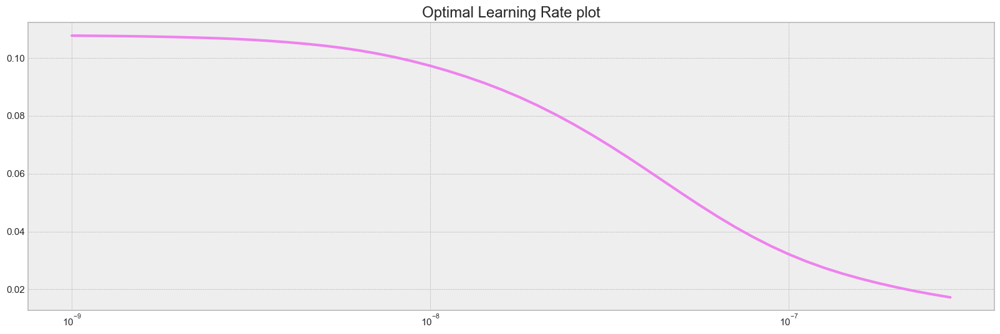

In [251]:
lr_(m,50)

* optimal learning rate based on the model will be less than 1e-6.

Epoch 1/300

200/200 [==============================] - 2s 4ms/step - loss: 0.0191 - mse: 0.0383 - mae: 0.1610

Epoch 2/300

200/200 [==============================] - 1s 4ms/step - loss: 0.0090 - mse: 0.0181 - mae: 0.1096

Epoch 3/300

200/200 [==============================] - 1s 4ms/step - loss: 0.0069 - mse: 0.0139 - mae: 0.0939

Epoch 4/300

200/200 [==============================] - 1s 4ms/step - loss: 0.0061 - mse: 0.0123 - mae: 0.0902

Epoch 5/300

200/200 [==============================] - 1s 4ms/step - loss: 0.0052 - mse: 0.0104 - mae: 0.0814

Epoch 6/300

200/200 [==============================] - 1s 4ms/step - loss: 0.0056 - mse: 0.0112 - mae: 0.0871

Epoch 7/300

200/200 [==============================] - 1s 4ms/step - loss: 0.0025 - mse: 0.0050 - mae: 0.0552

Epoch 8/300

200/200 [==============================] - 1s 4ms/step - loss: 0.0059 - mse: 0.0119 - mae: 0.0869

Epoch 9/300

200/200 [==============================] - 1s 4ms/step - loss: 0.0059 - mse: 0.0117 - mae: 

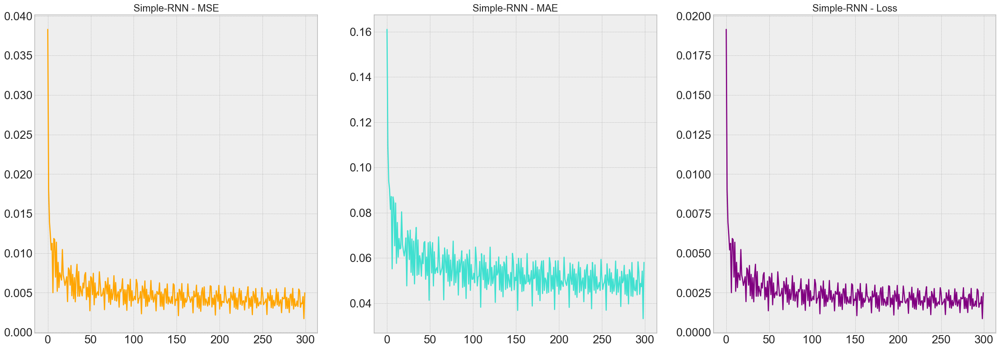

In [265]:
d,simplernn=model_fits(m,'Simple-RNN',1e-6,300)

14/14 [==============================] - 0s 5ms/step


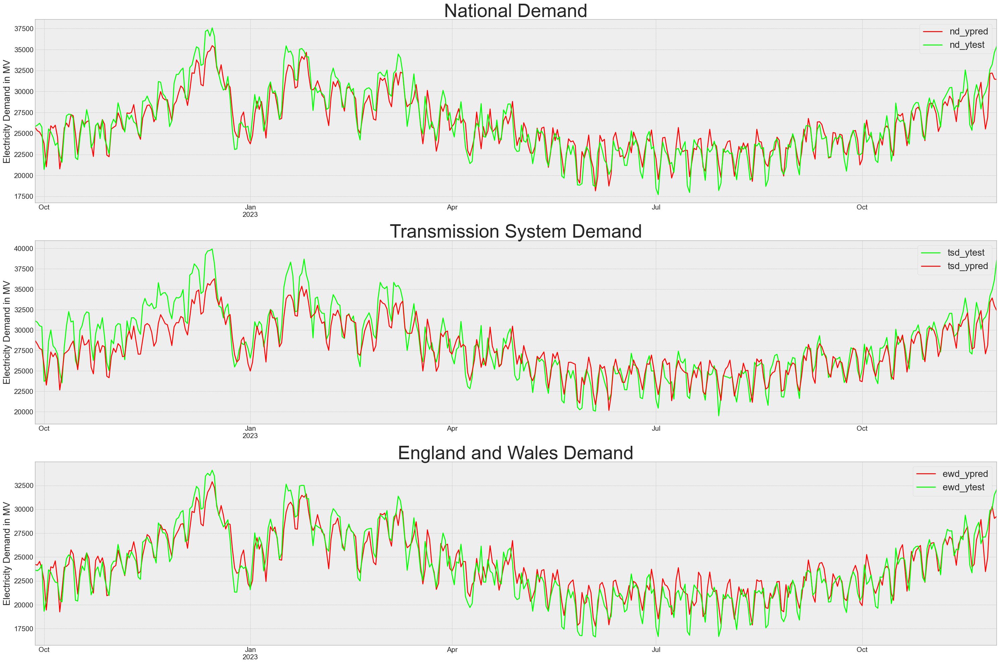

In [266]:
c,mt=predict_withplot(simplernn,xtest_combined)

In [268]:
mt

,National Demand,Transmission System Demand,England and Wales Demand
Mean Squared Error,2145599.0,3604549.0,1816562.0
Squared Root (mse),1465.0,1899.0,1348.0
Mean Absolute Error,1151.0,1517.0,1069.0
Mean Absolute Percentage Error,0.0,0.0,0.0


In [269]:
rnnforecast=forecasts(simplernn,366)

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 19ms/step

1/1 [==============================] - 0s 18ms/step

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 18ms/step

1/1 [==============================] - 0s 17ms/step

1/1 [==============================] - 0s 17ms/step

1/1 [==============================] - 0s 18ms/step

1/1 [==============================] - 0s 19ms/step

1/1 [==============================] - 0s 18ms/step

1/1 [==============================] - 0s 18ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 19ms/step

1/1 [==============================] - 0s 18ms/step

1/1 [==============================] - 0s 19ms

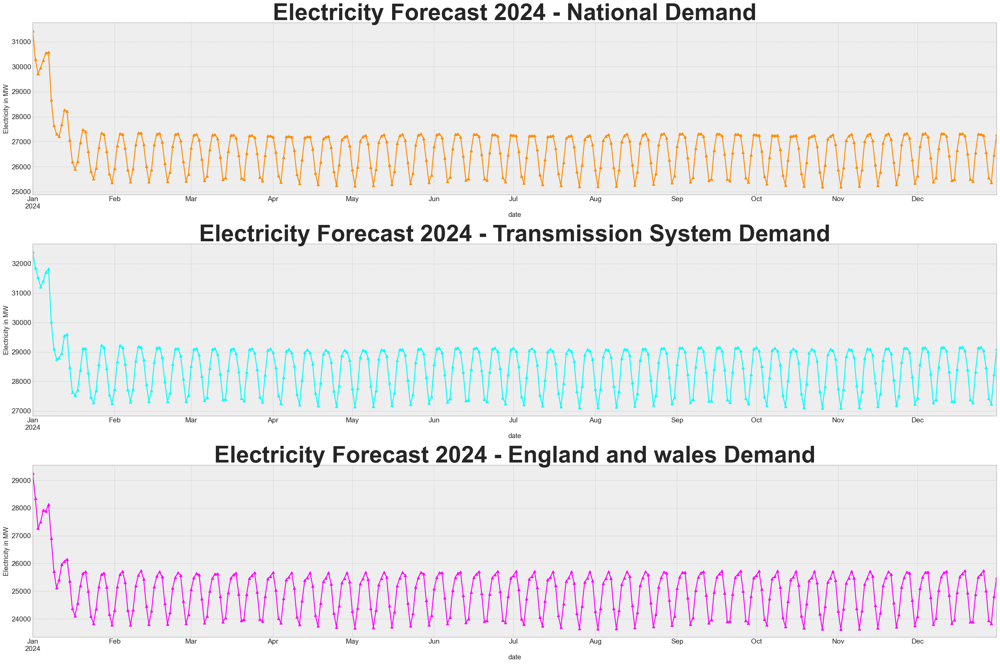

In [270]:
f_2024(rnnforecast)

# BI-DIRECTIONAL RNN MODEL


In [265]:
bm=Sequential([Bidirectional(SimpleRNN(units=300,return_sequences=True,
                                       input_shape=(xtrain_combined.shape[1],xtrain_combined.shape[2]),name='BRl1')),
               
               Bidirectional(SimpleRNN(units=200,name='Rl2',return_sequences=True)),
               
               Bidirectional(SimpleRNN(units=100,name='Rl3',return_sequences=True)),
               
               Bidirectional(SimpleRNN(units=45,name='Rl4',return_sequences=False)),
               
               Dense(units=45,activation='LeakyReLU',name='Dense1'), 
               
               Dense(units=10,activation='LeakyReLU',name='Dense2'),
               
               Dense(units=3,activation='linear',name=f'Final_layer_with_{num_features}_output')]) 

In [274]:
print(bm.summary()) 

Model: "sequential_31"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 bidirectional_80 (Bidirect  (None, 24, 600)           182400    

 ional)                                                          

                                                                 

 bidirectional_81 (Bidirect  (None, 24, 400)           320400    

 ional)                                                          

                                                                 

 bidirectional_82 (Bidirect  (None, 24, 200)           100200    

 ional)                                                          

                                                                 

 bidirectional_83 (Bidirect  (None, 90)                22140     

 ional)                                                          

                                                                 

 Dense1 (Dense)              (None, 4

Epoch 1/50

1708/1708 [==============================] - 59s 32ms/step - loss: 0.0057 - lr: 1.0000e-09

Epoch 2/50

1708/1708 [==============================] - 59s 34ms/step - loss: 0.0056 - lr: 1.1220e-09

Epoch 3/50

1708/1708 [==============================] - 59s 34ms/step - loss: 0.0055 - lr: 1.2589e-09

Epoch 4/50

1708/1708 [==============================] - 59s 35ms/step - loss: 0.0054 - lr: 1.4125e-09

Epoch 5/50

1708/1708 [==============================] - 59s 35ms/step - loss: 0.0053 - lr: 1.5849e-09

Epoch 6/50

1708/1708 [==============================] - 59s 35ms/step - loss: 0.0052 - lr: 1.7783e-09

Epoch 7/50

1708/1708 [==============================] - 60s 35ms/step - loss: 0.0050 - lr: 1.9953e-09

Epoch 8/50

1708/1708 [==============================] - 60s 35ms/step - loss: 0.0049 - lr: 2.2387e-09

Epoch 9/50

1708/1708 [==============================] - 59s 35ms/step - loss: 0.0047 - lr: 2.5119e-09

Epoch 10/50

1708/1708 [==============================] - 60s 35

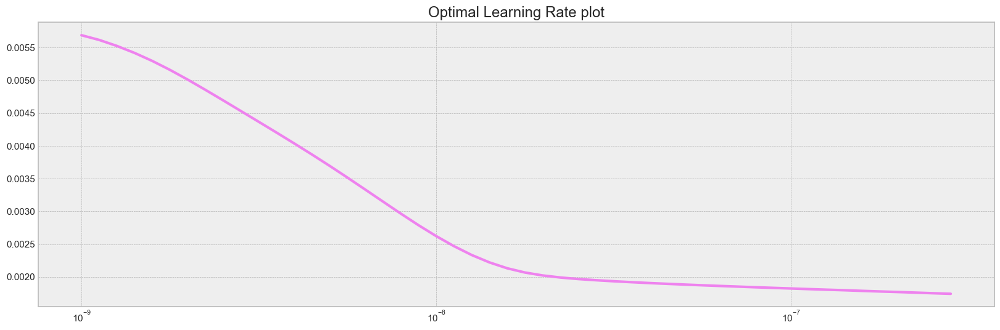

In [271]:
lr_(bm,50)

* optimal learning rate based on the model will be less than 1e-7.

Epoch 1/200

200/200 [==============================] - 10s 28ms/step - loss: 0.0917 - mse: 0.1876 - mae: 0.3032

Epoch 2/200

200/200 [==============================] - 6s 29ms/step - loss: 0.0200 - mse: 0.0399 - mae: 0.1603

Epoch 3/200

200/200 [==============================] - 6s 29ms/step - loss: 0.0098 - mse: 0.0195 - mae: 0.1087

Epoch 4/200

200/200 [==============================] - 6s 29ms/step - loss: 0.0094 - mse: 0.0188 - mae: 0.1115

Epoch 5/200

200/200 [==============================] - 6s 29ms/step - loss: 0.0073 - mse: 0.0146 - mae: 0.0966

Epoch 6/200

200/200 [==============================] - 6s 31ms/step - loss: 0.0077 - mse: 0.0154 - mae: 0.1000

Epoch 7/200

200/200 [==============================] - 6s 31ms/step - loss: 0.0030 - mse: 0.0059 - mae: 0.0602

Epoch 8/200

200/200 [==============================] - 6s 31ms/step - loss: 0.0073 - mse: 0.0146 - mae: 0.0974

Epoch 9/200

200/200 [==============================] - 6s 31ms/step - loss: 0.0089 - mse: 0.01

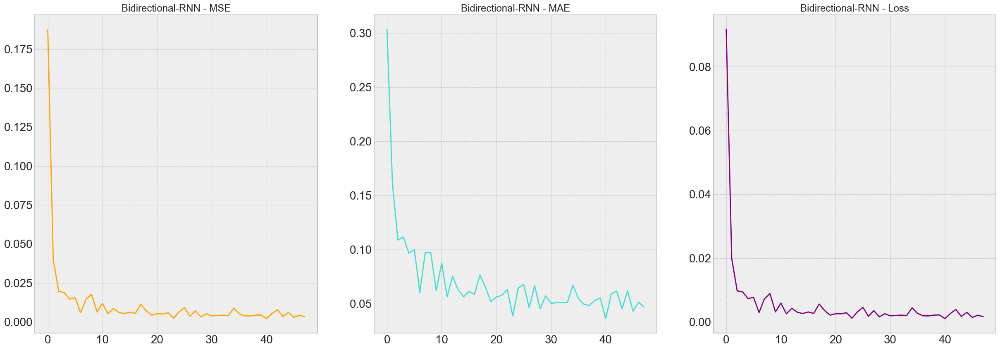

In [266]:
bhistory,brnn=model_fits(bm,'Bidirectional-RNN',1e-7,200) 

14/14 [==============================] - 2s 101ms/step


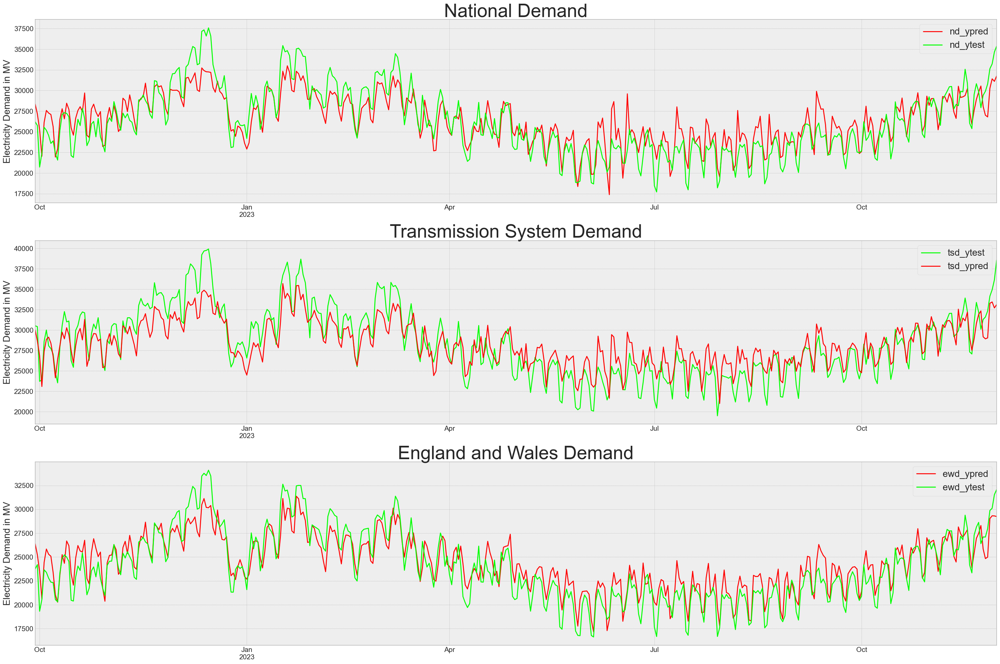

In [267]:
brnnframe,brnn_metrics=predict_withplot(brnn,xtest_combined)  

In [268]:
brnn_metrics

,National Demand,Transmission System Demand,England and Wales Demand
Mean Squared Error,3965580.0,4534598.0,2622502.0
Squared Root (mse),1991.0,2129.0,1619.0
Mean Absolute Error,1576.0,1747.0,1312.0
Mean Absolute Percentage Error,0.0,0.0,0.0


In [269]:
brnnforecast=forecasts(brnn,366)

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 27ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms

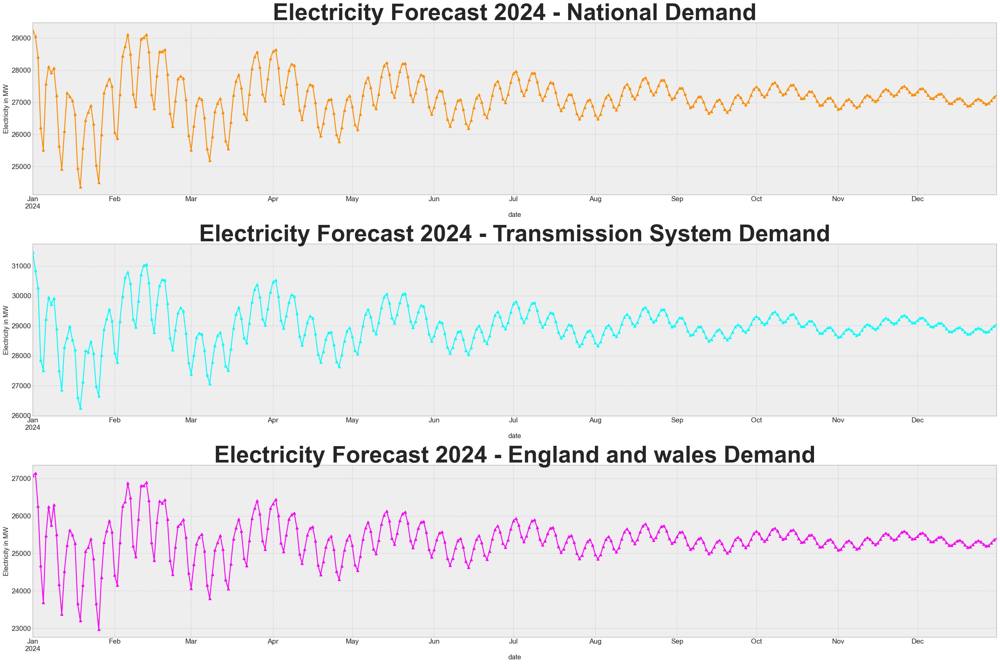

In [270]:
brnn.save('bidirectionalrnn model.h5')
f_2024(brnnforecast)

# LSTM

    * Long Short-Term Memory (LSTM) is one of the (RNN) architectures designed to address the vanishing gradient problem in traditional RNNs. 
    * This architecture is  particularly useful in tasks where sequences and dependencies play a crucial role, such as natural language processing, speech recognition, and time series analysis. And its gates are,

    * Forget Gate:

        Purpose: Determines what information from the cell state should be discarded or kept.
        Activation: Sigmoid function.
    
    * Input Gate:

        Purpose: Determines what new information to store in the cell state.
        Activation: Sigmoid function.
        
    * Cell State Update:

        Purpose: Updates the cell state with new information.
        Activation: Tanh function.
        
    * Output Gate:

        Purpose: Determines the next hidden state and also the output of the cell.
        Activation: Sigmoid function.

In [68]:
ls = Sequential([
    LSTM(units=80, return_sequences=True, activation='relu', 
         input_shape=(xtrain_combined.shape[1], xtrain_combined.shape[2]), name='lstm1'),
    
    LSTM(units=60, return_sequences=True, name='lstm2', activation='relu'),
    
    LSTM(units=60, return_sequences=True, name='lstm3', activation='relu'),
    
    LSTM(units=60, return_sequences=True, name='lstm4', activation='relu'),
    
    LSTM(units=60, return_sequences=False, name='lstm5', activation='relu'),
  
    Dense(units=184, activation='relu'),
    
    Dense(units=162, activation='relu'),
    
    Dense(units=127, activation='relu'),
    
    Dense(units=56, activation='relu',),
    
    Dense(units=36, activation='relu'),
    
    Dense(units=27, activation='relu'), 
    
    Dense(units=9, activation='relu'), 
    
    Dense(units=6, activation='relu'),
    
    Dense(units=num_features, activation='linear', name=f'Final_layer_with_{num_features}_output')
])


Epoch 1/100

200/200 [==============================] - 7s 10ms/step - loss: 0.0047 - lr: 1.0000e-09

Epoch 2/100

200/200 [==============================] - 2s 10ms/step - loss: 0.0057 - lr: 1.1220e-09

Epoch 3/100

200/200 [==============================] - 2s 10ms/step - loss: 0.0029 - lr: 1.2589e-09

Epoch 4/100

200/200 [==============================] - 2s 10ms/step - loss: 0.0032 - lr: 1.4125e-09

Epoch 5/100

200/200 [==============================] - 2s 10ms/step - loss: 0.0020 - lr: 1.5849e-09

Epoch 6/100

200/200 [==============================] - 2s 10ms/step - loss: 0.0044 - lr: 1.7783e-09

Epoch 7/100

200/200 [==============================] - 2s 10ms/step - loss: 0.0023 - lr: 1.9953e-09

Epoch 8/100

200/200 [==============================] - 2s 10ms/step - loss: 0.0022 - lr: 2.2387e-09

Epoch 9/100

200/200 [==============================] - 2s 10ms/step - loss: 0.0037 - lr: 2.5119e-09

Epoch 10/100

200/200 [==============================] - 2s 10ms/step - loss: 0.00

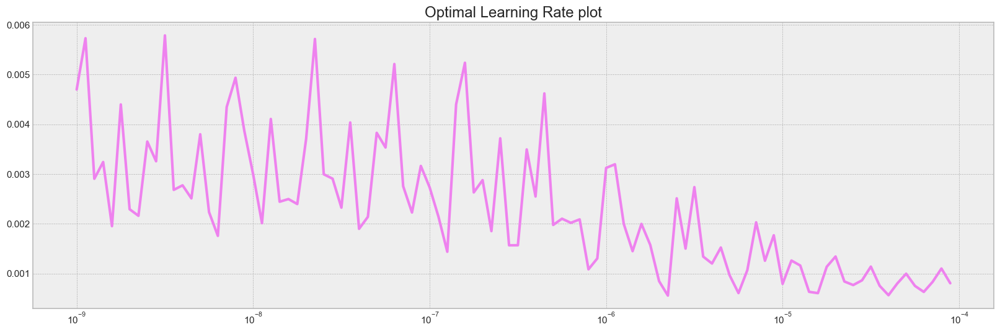

In [77]:
lr_(ls,100)

* optimal learning rate based on the model will be less than 1e-4.

Model: "sequential_7"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 lstm1 (LSTM)                (None, 12, 80)            26880     

                                                                 

 lstm2 (LSTM)                (None, 12, 60)            33840     

                                                                 

 lstm3 (LSTM)                (None, 12, 60)            29040     

                                                                 

 lstm4 (LSTM)                (None, 12, 60)            29040     

                                                                 

 lstm5 (LSTM)                (None, 60)                29040     

                                                                 

 dense_5 (Dense)             (None, 184)               11224     

                                                                 

 dense_6 (Dense)             (None, 16

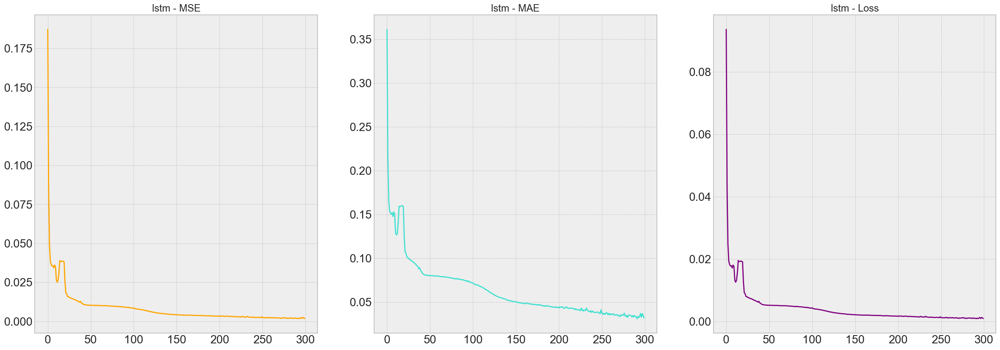

In [69]:
lshistory,ls=model_fits(ls,'lstm',1e-4,300) 

14/14 [==============================] - 1s 7ms/step


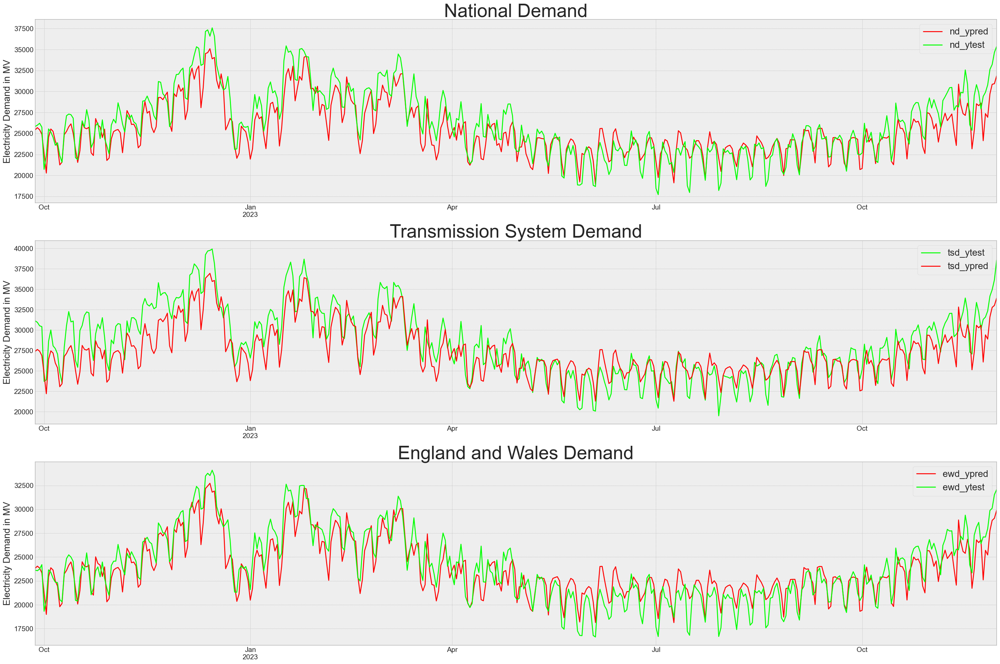

In [70]:
ls=tf.keras.models.load_model("C:/Users/Sethu/Downloads/save besgt/savebestonlymodel.h5")
lsframe,ls_metrics=predict_withplot(ls,xtest_combined) 

In [71]:
ls_metrics

,National Demand,Transmission System Demand,England and Wales Demand
Mean Squared Error,3792830.0,4969600.0,2668351.0
Squared Root (mse),1948.0,2229.0,1634.0
Mean Absolute Error,1531.0,1814.0,1293.0
Mean Absolute Percentage Error,0.0,0.0,0.0


In [72]:
lstmforecast=forecasts(ls,366)

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 32ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 21ms

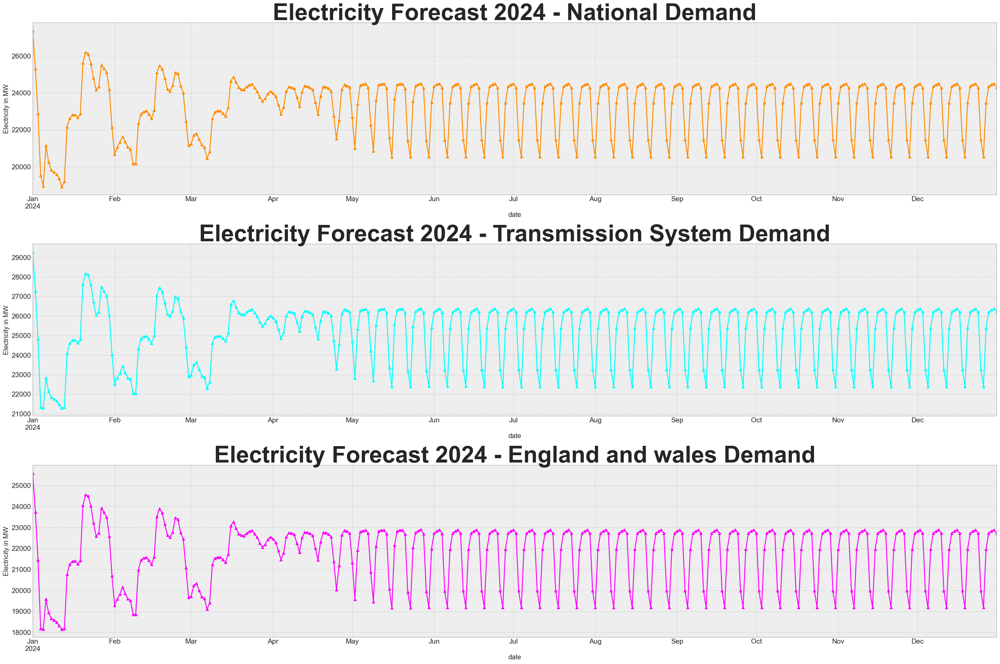

In [74]:
f_2024(lstmforecast)

# BIDIRECTIONAL LSTM

    * Bidirectional LSTMs process input sequences in both the forward and backward directions simultaneously, effectively capturing information from past and future contexts.
    * In a Bidirectional LSTM, there are two sets of hidden states, one for the forward processing and another for the backward processing. 
    * These hidden states are typically concatenated or combined in some way to provide a comprehensive representation.
    * Training bidirectional LSTMs may require more computational resources compared to their unidirectional counterparts.

In [102]:
bils = Sequential([
    Bidirectional(LSTM(units=100, return_sequences=True, activation='relu', 
         input_shape=(xtrain_combined.shape[1], xtrain_combined.shape[2]), name='lstm1')),
  
    Bidirectional(LSTM(units=100, return_sequences=True, name='lstm2', activation='relu')),
    
    Bidirectional(LSTM(units=100, return_sequences=True, name='lstm3', activation='relu')),
    
    Bidirectional(LSTM(units=60, return_sequences=True, name='lstm4', activation='relu')),
    
    Bidirectional(LSTM(units=60, return_sequences=False, name='lstm5', activation='relu')),
  
    Dense(units=184, activation='relu'),
    
    Dense(units=162, activation='relu'),
    
    Dense(units=127, activation='relu'),
    
    Dense(units=56, activation='relu',),
    
    Dense(units=36, activation='relu'),
    
    Dense(units=27, activation='relu'), 
    
    Dense(units=9, activation='relu'), 
    
    Dense(units=6, activation='relu'),
    
    Dense(units=num_features, activation='linear', name=f'Final_layer_with_{num_features}_output')
])

Epoch 1/100

200/200 [==============================] - 12s 19ms/step - loss: 0.0075 - lr: 1.0000e-09

Epoch 2/100

200/200 [==============================] - 4s 19ms/step - loss: 0.0081 - lr: 1.1220e-09

Epoch 3/100

200/200 [==============================] - 4s 19ms/step - loss: 0.0040 - lr: 1.2589e-09

Epoch 4/100

200/200 [==============================] - 4s 19ms/step - loss: 0.0086 - lr: 1.4125e-09

Epoch 5/100

200/200 [==============================] - 4s 19ms/step - loss: 0.0014 - lr: 1.5849e-09

Epoch 6/100

200/200 [==============================] - 4s 19ms/step - loss: 0.0076 - lr: 1.7783e-09

Epoch 7/100

200/200 [==============================] - 4s 19ms/step - loss: 0.0020 - lr: 1.9953e-09

Epoch 8/100

200/200 [==============================] - 4s 20ms/step - loss: 0.0056 - lr: 2.2387e-09

Epoch 9/100

200/200 [==============================] - 4s 19ms/step - loss: 0.0058 - lr: 2.5119e-09

Epoch 10/100

200/200 [==============================] - 4s 19ms/step - loss: 0.0

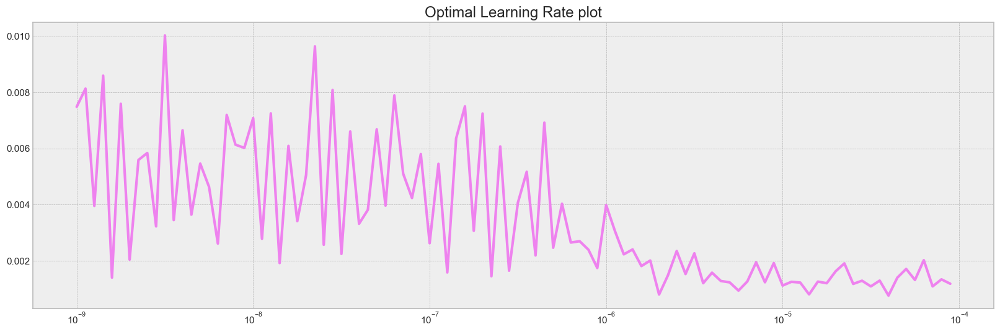

In [113]:
lr_(bils,100)

* optimal learning rate based on the model will be less than 1e-4.

Epoch 1/300

1718/1718 [==============================] - ETA: 0s - loss: 0.0263 - mse: 0.0527 - mae: 0.1519

Epoch 1: mae improved from inf to 0.15186, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 38s 18ms/step - loss: 0.0263 - mse: 0.0527 - mae: 0.1519

Epoch 2/300

1716/1718 [============================>.] - ETA: 0s - loss: 0.0083 - mse: 0.0165 - mae: 0.1004

Epoch 2: mae improved from 0.15186 to 0.10031, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 34s 20ms/step - loss: 0.0082 - mse: 0.0165 - mae: 0.1003

Epoch 3/300

1716/1718 [============================>.] - ETA: 0s - loss: 0.0091 - mse: 0.0181 - mae: 0.1045

Epoch 3: mae did not improve from 0.10031

1718/1718 [==============================] - 34s 20ms/step - loss: 0.0091 - mse: 0.0181 - mae: 0.1044

Epoch 4/300

1718/1718 [==============================] - ETA: 0s - loss: 0.0102

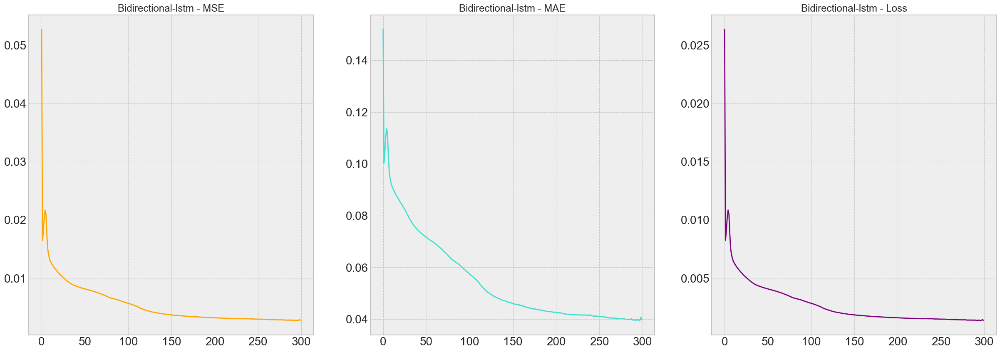

In [103]:
bilshistory,bils=model_fits(bils,'Bidirectional-lstm',1e-4,300) 

14/14 [==============================] - 0s 9ms/step


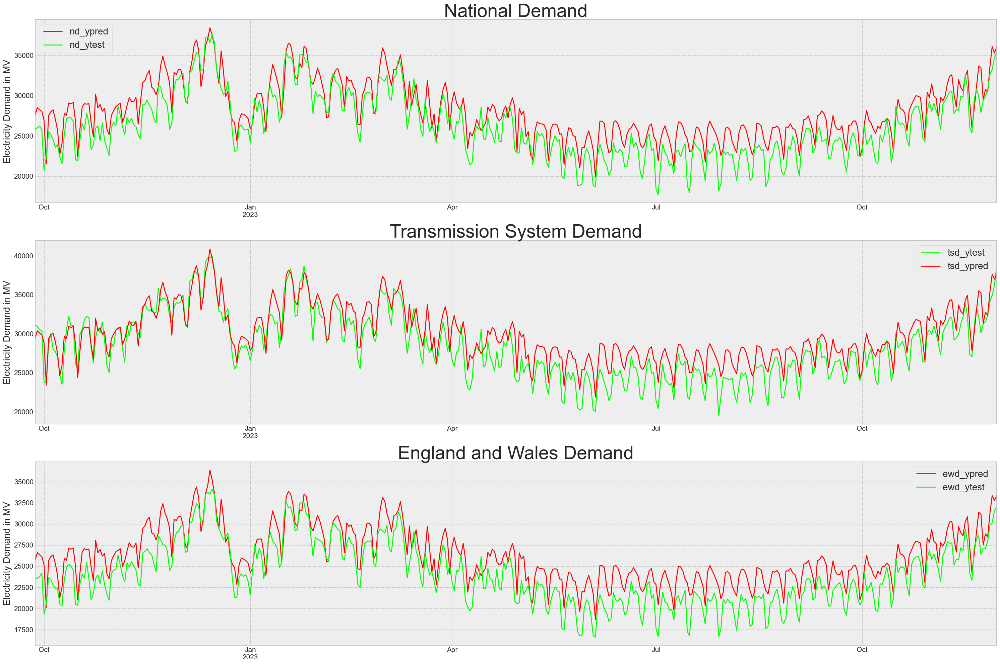

In [104]:
bils=tf.keras.models.load_model("C:/Users/Sethu/Downloads/save besgt/savebestonlymodel.h5")
bilsframe,bils_metrics=predict_withplot(ls,xtest_combined) 

In [105]:
bils_metrics

,National Demand,Transmission System Demand,England and Wales Demand
Mean Squared Error,6234142.0,5483910.0,7014201.0
Squared Root (mse),2497.0,2342.0,2648.0
Mean Absolute Error,2108.0,1901.0,2309.0
Mean Absolute Percentage Error,0.0,0.0,0.0


In [111]:
bilstmforecast=forecasts(bils,366)

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 33ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 24ms

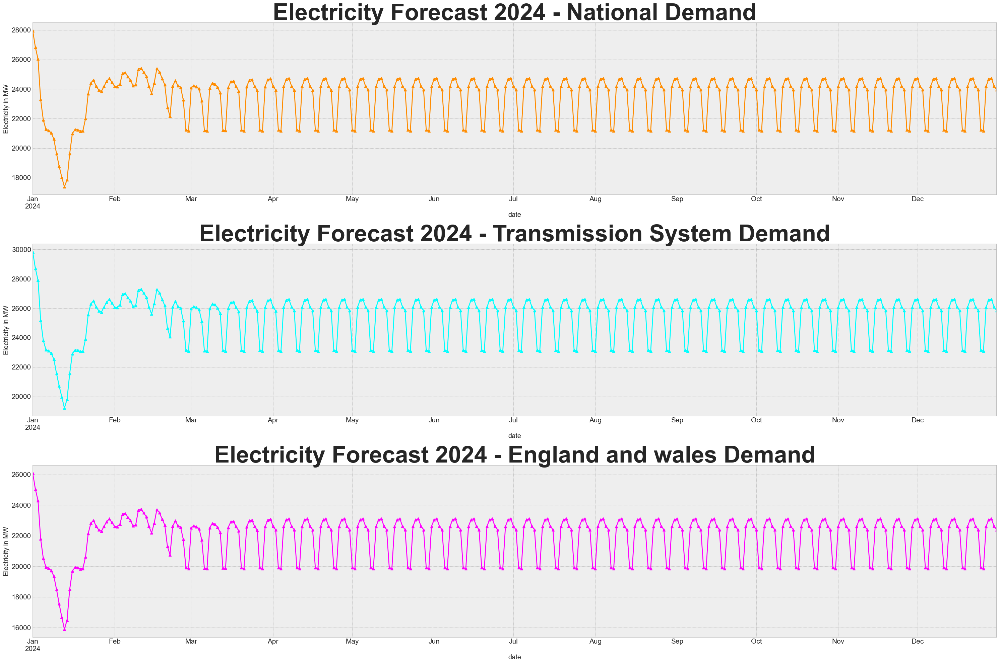

In [112]:
f_2024(bilstmforecast)

# GRU MODEL

    * GRU has a simpler architecture compared to Long Short-Term Memory (LSTM). 
    * It consists of two gates, namely the reset gate and the update gate, which makes it computationally less intensive and easier to train.
    * GRU is often considered effective for capturing short-term dependencies in sequential data. 
    * It may perform well in tasks where retaining recent information is more critical than maintaining long-term dependencies.

    * Update Gate:

        Purpose: Determines the extent to which the previous memory should be updated with the new information.
        Activation: Sigmoid function.
        
    * Reset Gate:

        Purpose: Decides how much of the previous memory to forget.
        Activation: Sigmoid function.
        
    * Hidden State Update:

        Purpose: Computes the new hidden state based on the current input, the previous hidden state (after considering the reset gate), and the updated memory.
        Activation: Typically uses a hyperbolic tangent (tanh) or another activation function.

In [78]:
grum=tf.keras.Sequential([GRU(units=100,activation='tanh',return_sequences=True,
                            input_shape=(xtrain_combined.shape[1],xtrain_combined.shape[2]),name='gru1'),
                          
                        GRU(units=100,activation='tanh',return_sequences=True,name='gru2'),
                        
                        Dense(units=50,activation='LeakyReLU'),
                          
                        Dense(units=25,activation='LeakyReLU'),
                          
                        Dense(units=9,activation='LeakyReLU'),
                        
                        Dense(units=num_features, activation='linear', name=f'Final_layer_with_{num_features}_output')
                        ])

In [46]:
grum.summary()

Model: "sequential_4"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 gru1 (GRU)                  (None, 12, 100)           31500     

                                                                 

 gru2 (GRU)                  (None, 12, 100)           60600     

                                                                 

 dense_15 (Dense)            (None, 12, 50)            5050      

                                                                 

 dense_16 (Dense)            (None, 12, 25)            1275      

                                                                 

 dense_17 (Dense)            (None, 12, 9)             234       

                                                                 

 Final_layer_with_3_output   (None, 12, 3)             30        

 (Dense)                                                         

                                      

Epoch 1/100

200/200 [==============================] - 4s 6ms/step - loss: 0.1877 - lr: 1.0000e-09

Epoch 2/100

200/200 [==============================] - 1s 6ms/step - loss: 0.1995 - lr: 1.1220e-09

Epoch 3/100

200/200 [==============================] - 1s 6ms/step - loss: 0.1047 - lr: 1.2589e-09

Epoch 4/100

200/200 [==============================] - 1s 6ms/step - loss: 0.2007 - lr: 1.4125e-09

Epoch 5/100

200/200 [==============================] - 1s 6ms/step - loss: 0.0451 - lr: 1.5849e-09

Epoch 6/100

200/200 [==============================] - 1s 6ms/step - loss: 0.1842 - lr: 1.7783e-09

Epoch 7/100

200/200 [==============================] - 1s 6ms/step - loss: 0.0785 - lr: 1.9953e-09

Epoch 8/100

200/200 [==============================] - 1s 6ms/step - loss: 0.1564 - lr: 2.2387e-09

Epoch 9/100

200/200 [==============================] - 1s 6ms/step - loss: 0.1519 - lr: 2.5119e-09

Epoch 10/100

200/200 [==============================] - 1s 7ms/step - loss: 0.0976 - lr: 2

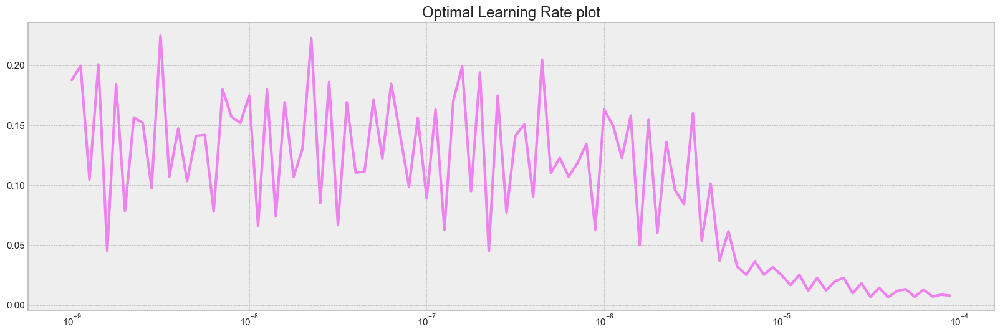

In [79]:
lr_(grum,100)

* optimal learning rate based on the model will be less than 1e-4.

Epoch 1/300

1716/1718 [============================>.] - ETA: 0s - loss: 0.0086 - mse: 0.0171 - mae: 0.0994

Epoch 1: mae improved from inf to 0.09932, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 13s 6ms/step - loss: 0.0085 - mse: 0.0171 - mae: 0.0993

Epoch 2/300

1716/1718 [============================>.] - ETA: 0s - loss: 0.0074 - mse: 0.0148 - mae: 0.0964

Epoch 2: mae improved from 0.09932 to 0.09635, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 10s 6ms/step - loss: 0.0074 - mse: 0.0148 - mae: 0.0963

Epoch 3/300

1714/1718 [============================>.] - ETA: 0s - loss: 0.0078 - mse: 0.0156 - mae: 0.0985

Epoch 3: mae did not improve from 0.09635

1718/1718 [==============================] - 10s 6ms/step - loss: 0.0078 - mse: 0.0156 - mae: 0.0984

Epoch 4/300

1711/1718 [============================>.] - ETA: 0s - loss: 0.0084 - 

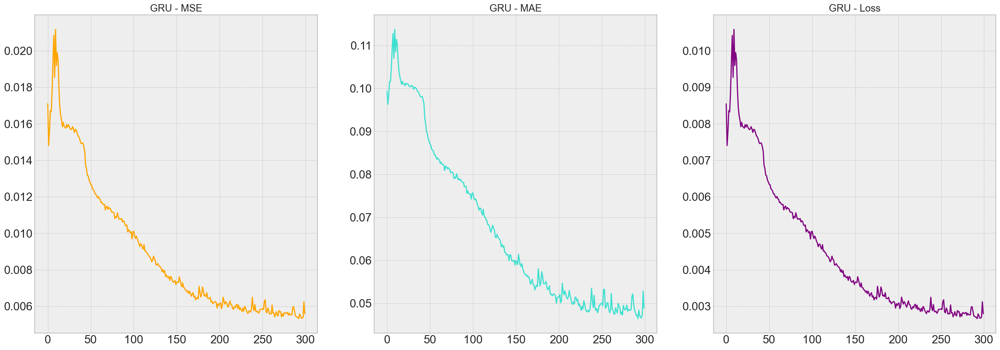

In [26]:
gruhistory,gru=model_fits(grum,'GRU',1e-4,300) 

14/14 [==============================] - 1s 6ms/step


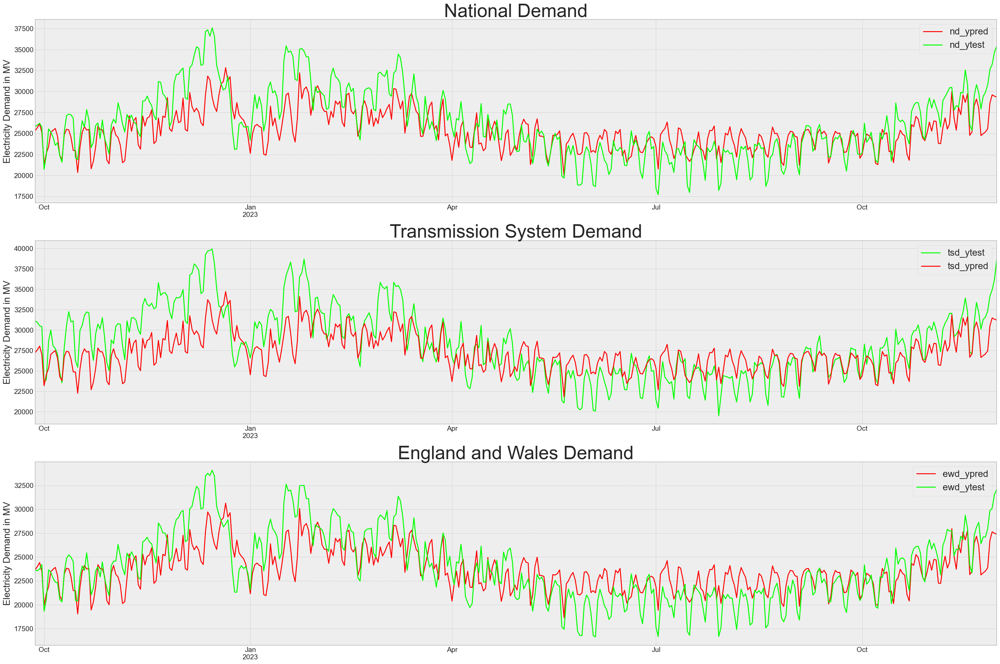

In [52]:
gru=tf.keras.models.load_model("C:/Users/Sethu/Downloads/save besgt/savebestonlymodel.h5")
gruframe,gru_metrics=predict_withplot(gru,xtest_combined) 

In [28]:
gru_metrics

,National Demand,Transmission System Demand,England and Wales Demand
Mean Squared Error,7756762.0,9667411.0,5967167.0
Squared Root (mse),2785.0,3109.0,2443.0
Mean Absolute Error,2169.0,2444.0,1943.0
Mean Absolute Percentage Error,0.0,0.0,0.0


In [54]:
gruforecast=forecasts(gru,366)

1/1 [==============================] - 0s 29ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 28ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 27ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 37ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 31ms

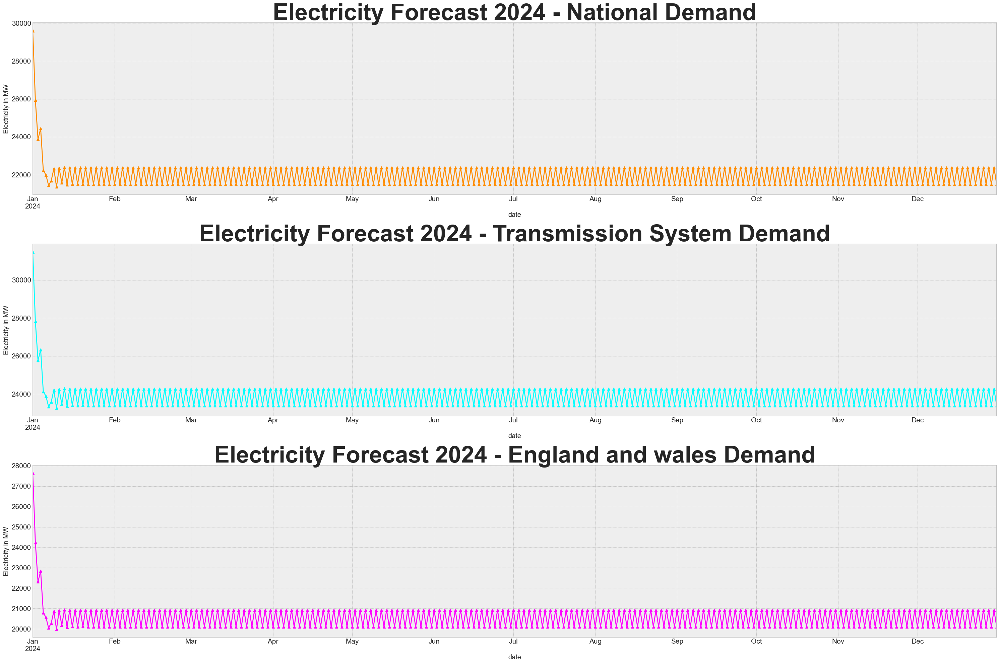

In [55]:
f_2024(gruforecast)

# BIDIRECTIONAL GRU

    * Bidirectional GRUs follow a similar concept as Bidirectional LSTMs but with the simpler structure of GRUs. 
    * They process input sequences in both directions, maintaining the reset and update gates for each direction.
    * As usual same gates will be here with the GRU.
    * Bidirectional GRUs often have a faster training speed compared to Bidirectional LSTMs due to the simpler structure of GRUs

In [73]:
bigrum=tf.keras.Sequential([Bidirectional(GRU(units=100,activation='tanh',return_sequences=True,
                            input_shape=(xtrain_combined.shape[1],xtrain_combined.shape[2]),name='gru1')),
                            
                        Bidirectional(GRU(units=100,activation='tanh',return_sequences=True,name='gru2')),
                            
                        Bidirectional(GRU(units=100,activation='tanh',return_sequences=True,name='gru3')),
                       
                        Dense(units=50,activation='LeakyReLU'),
                            
                        Dense(units=25,activation='LeakyReLU'),
                            
                        Dense(units=9,activation='LeakyReLU'),
                        
                        Dense(units=num_features, activation='linear', name=f'Final_layer_with_{num_features}_output')])


In [76]:
bigrum.summary()

Model: "sequential_9"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 bidirectional_11 (Bidirect  (1, 12, 200)              63000     

 ional)                                                          

                                                                 

 bidirectional_12 (Bidirect  (1, 12, 200)              181200    

 ional)                                                          

                                                                 

 bidirectional_13 (Bidirect  (1, 12, 200)              181200    

 ional)                                                          

                                                                 

 dense_30 (Dense)            (1, 12, 50)               10050     

                                                                 

 dense_31 (Dense)            (1, 12, 25)               1275      

                                      

Epoch 1/100

200/200 [==============================] - 12s 12ms/step - loss: 0.0088 - lr: 1.0000e-09

Epoch 2/100

200/200 [==============================] - 2s 12ms/step - loss: 0.0105 - lr: 1.1220e-09

Epoch 3/100

200/200 [==============================] - 3s 13ms/step - loss: 0.0060 - lr: 1.2589e-09

Epoch 4/100

200/200 [==============================] - 3s 13ms/step - loss: 0.0102 - lr: 1.4125e-09

Epoch 5/100

200/200 [==============================] - 3s 13ms/step - loss: 0.0024 - lr: 1.5849e-09

Epoch 6/100

200/200 [==============================] - 2s 12ms/step - loss: 0.0105 - lr: 1.7783e-09

Epoch 7/100

200/200 [==============================] - 3s 13ms/step - loss: 0.0036 - lr: 1.9953e-09

Epoch 8/100

200/200 [==============================] - 3s 13ms/step - loss: 0.0068 - lr: 2.2387e-09

Epoch 9/100

200/200 [==============================] - 2s 12ms/step - loss: 0.0059 - lr: 2.5119e-09

Epoch 10/100

200/200 [==============================] - 2s 12ms/step - loss: 0.0

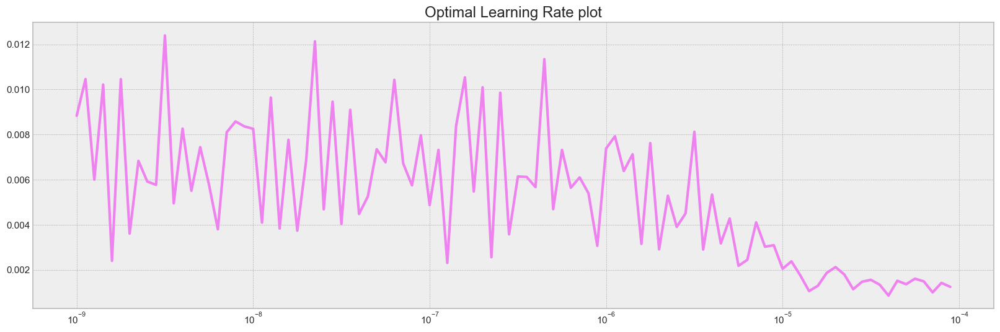

In [77]:
lr_(bigrum,100)

* optimal learning rate based on the model will be less than 1e-3.

Epoch 1/100

1716/1718 [============================>.] - ETA: 0s - loss: 0.0082 - mse: 0.0165 - mae: 0.0996

Epoch 1: mae improved from inf to 0.09959, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 39s 17ms/step - loss: 0.0082 - mse: 0.0165 - mae: 0.0996

Epoch 2/100

1714/1718 [============================>.] - ETA: 0s - loss: 0.0069 - mse: 0.0138 - mae: 0.0936

Epoch 2: mae improved from 0.09959 to 0.09354, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 24s 14ms/step - loss: 0.0069 - mse: 0.0138 - mae: 0.0935

Epoch 3/100

1717/1718 [============================>.] - ETA: 0s - loss: 0.0078 - mse: 0.0155 - mae: 0.0985

Epoch 3: mae did not improve from 0.09354

1718/1718 [==============================] - 17s 10ms/step - loss: 0.0078 - mse: 0.0155 - mae: 0.0984

Epoch 4/100

1717/1718 [============================>.] - ETA: 0s - loss: 0.0077

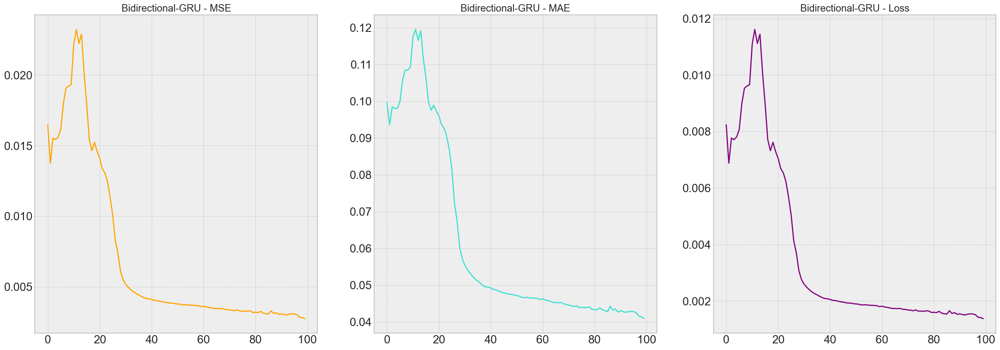

In [75]:
bigruhistory,bigru=model_fits(bigrum,'Bidirectional-GRU',1e-3,100) 

14/14 [==============================] - 2s 10ms/step


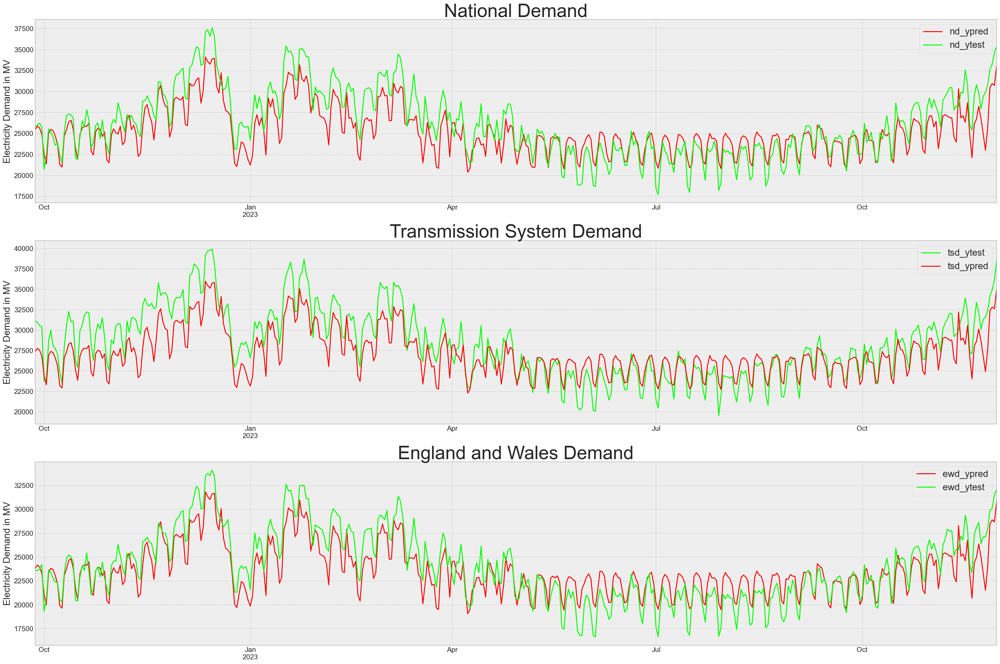

In [80]:
bigru=tf.keras.models.load_model("C:/Users/Sethu/Downloads/save besgt/savebestonlymodel.h5")
bigruframe,bigru_metrics=predict_withplot(bigru,xtest_combined) #

In [81]:
bigru_metrics#

,National Demand,Transmission System Demand,England and Wales Demand
Mean Squared Error,4862814.0,6220262.0,3485477.0
Squared Root (mse),2205.0,2494.0,1867.0
Mean Absolute Error,1799.0,2082.0,1550.0
Mean Absolute Percentage Error,0.0,0.0,0.0


In [82]:
bigruforecast=forecasts(bigru,366)

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 19ms/step

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 19ms/step

1/1 [==============================] - 0s 19ms/step

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 35ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 19ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 20ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 21ms/step

1/1 [==============================] - 0s 19ms

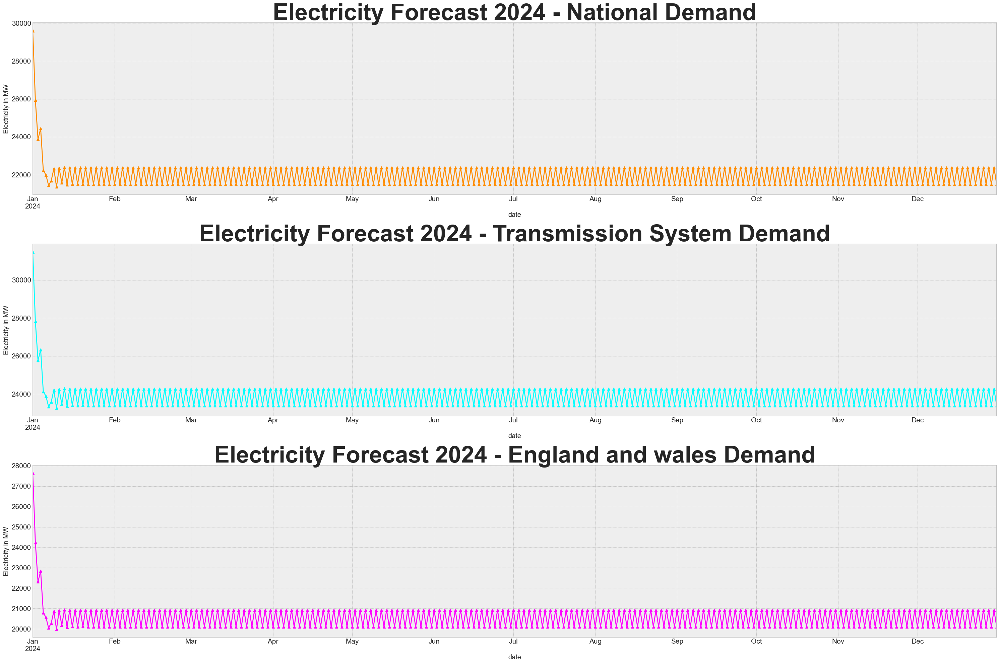

In [83]:
f_2024(gruforecast)

# HYBRID MODELS

In [96]:
from keras.layers import  Conv1D, MaxPooling1D, Flatten

   @ CONV1D LAYER:
   
    * Conv1D layers are designed to capture local patterns in sequential data. In the context of time series, this means they can identify short-term dependencies and patterns within specific windows of time.
    
    * Translation Invariance: Convolutional operations in the time domain provide a degree of translation invariance. This means the model can recognize patterns regardless of their specific position in the time series, which can be beneficial when the timing of events is not precisely known.
    
    * Parameter Sharing: Conv1D layers use parameter sharing, meaning the same set of weights is applied across different positions in the input sequence. This helps the model generalize well to different parts of the time series.
    
    * Downsampling: By using pooling layers after Conv1D layers, you can downsample the input sequence, reducing its length. This can be useful for focusing on the most important features and reducing the computational burden.
    
    * Feature Extraction: Conv1D layers act as feature extractors, automatically learning meaningful representations from the input time series. This is particularly advantageous when the time series contains complex patterns or when manual feature engineering is challenging.
    
    * Combination with Recurrent Layers: Conv1D layers can be combined with recurrent layers (e.g., LSTM or GRU) in a hybrid architecture. This allows the model to capture both local patterns (with Conv1D) and long-term dependencies (with recurrent layers) in the time series.
    
    * Multiscale Representations: Conv1D layers with different kernel sizes can capture patterns at multiple scales. This multiscale approach can enhance the model's ability to recognize features of various durations in the time series.
    
    * Anomaly Detection: Conv1D layers can be effective for detecting anomalies or outliers in time series data by learning normal patterns and identifying deviations from them.

# A) CONVOLUTION + LSTM+ DNN MODEL

In [170]:
cld=tf.keras.Sequential([Conv1D(filters=32,kernel_size=3,strides=1,padding='causal',activation='relu',
                               input_shape=(xtrain_combined.shape[1], xtrain_combined.shape[2])),
                         
                         Conv1D(filters=64,kernel_size=3,strides=1,padding='causal',activation='relu'),
                         
                         Conv1D(filters=128,kernel_size=3,padding='causal',activation='relu'),
                         
                         MaxPooling1D(pool_size=2,strides=1,padding='same'),
                         
                         Bidirectional(LSTM(units=120,activation='relu',return_sequences=True)),
                         
                         Bidirectional(LSTM(units=120,activation='relu',return_sequences=True)),
                         
                         Bidirectional(LSTM(units=120,activation='relu',return_sequences=True)),
                         
                         Bidirectional(LSTM(units=100,activation='relu',return_sequences=True)),
                         
                         LSTM(units=100,activation='relu',return_sequences=False),
                         
                         Dense(units=84,activation='relu'),
                         
                         Dense(units=77,activation='relu'),
                         
                         Dense(units=44,activation='relu'),
                         
                         Dense(units=22,activation='relu'),
                         
                         Dense(units=9,activation='relu'),
                         
                         Dense(units=num_features, activation='linear', name=f'Final_layer_with_{num_features}_output')   
    
])

In [171]:
cld.summary()

Model: "sequential_22"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 conv1d_25 (Conv1D)          (None, 12, 32)            320       

                                                                 

 conv1d_26 (Conv1D)          (None, 12, 64)            6208      

                                                                 

 conv1d_27 (Conv1D)          (None, 12, 128)           24704     

                                                                 

 max_pooling1d_9 (MaxPoolin  (None, 12, 128)           0         

 g1D)                                                            

                                                                 

 bidirectional_32 (Bidirect  (None, 12, 240)           239040    

 ional)                                                          

                                                                 

 bidirectional_33 (Bidirect  (None, 1

Epoch 1/100

200/200 [==============================] - 14s 24ms/step - loss: 0.1792 - lr: 1.0000e-09

Epoch 2/100

200/200 [==============================] - 5s 24ms/step - loss: 0.1908 - lr: 1.1220e-09

Epoch 3/100

200/200 [==============================] - 5s 25ms/step - loss: 0.1000 - lr: 1.2589e-09

Epoch 4/100

200/200 [==============================] - 5s 25ms/step - loss: 0.1918 - lr: 1.4125e-09

Epoch 5/100

200/200 [==============================] - 5s 26ms/step - loss: 0.0431 - lr: 1.5849e-09

Epoch 6/100

200/200 [==============================] - 5s 26ms/step - loss: 0.1761 - lr: 1.7783e-09

Epoch 7/100

200/200 [==============================] - 5s 26ms/step - loss: 0.0751 - lr: 1.9953e-09

Epoch 8/100

200/200 [==============================] - 5s 26ms/step - loss: 0.1490 - lr: 2.2387e-09

Epoch 9/100

200/200 [==============================] - 5s 27ms/step - loss: 0.1447 - lr: 2.5119e-09

Epoch 10/100

200/200 [==============================] - 5s 27ms/step - loss: 0.0

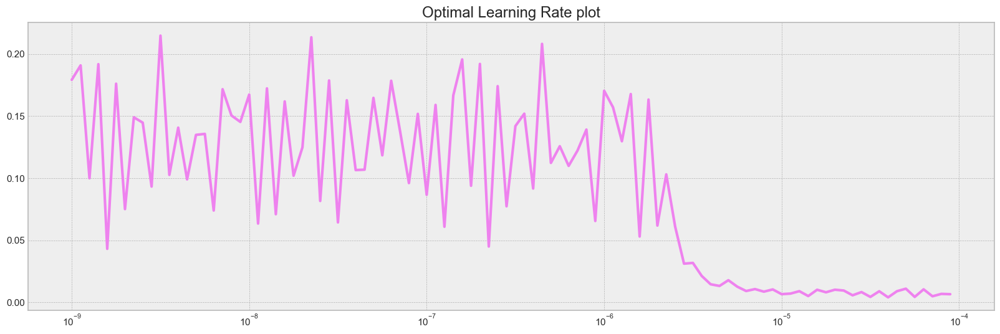

In [172]:
lr_(cld,100)

* optimal learning rate based on the model will be less than 1e-5.

Epoch 1/60

1717/1718 [============================>.] - ETA: 0s - loss: 0.0064 - mse: 0.0128 - mae: 0.0914

Epoch 1: mae improved from inf to 0.09137, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 56s 28ms/step - loss: 0.0064 - mse: 0.0128 - mae: 0.0914

Epoch 2/60

1717/1718 [============================>.] - ETA: 0s - loss: 0.0065 - mse: 0.0130 - mae: 0.0918

Epoch 2: mae did not improve from 0.09137

1718/1718 [==============================] - 48s 28ms/step - loss: 0.0065 - mse: 0.0130 - mae: 0.0918

Epoch 3/60

1717/1718 [============================>.] - ETA: 0s - loss: 0.0067 - mse: 0.0133 - mae: 0.0925

Epoch 3: mae did not improve from 0.09137

1718/1718 [==============================] - 50s 29ms/step - loss: 0.0067 - mse: 0.0133 - mae: 0.0925

Epoch 4/60

1718/1718 [==============================] - ETA: 0s - loss: 0.0068 - mse: 0.0137 - mae: 0.0935

Epoch 4: mae did not improve from 0.09137

1718/1718

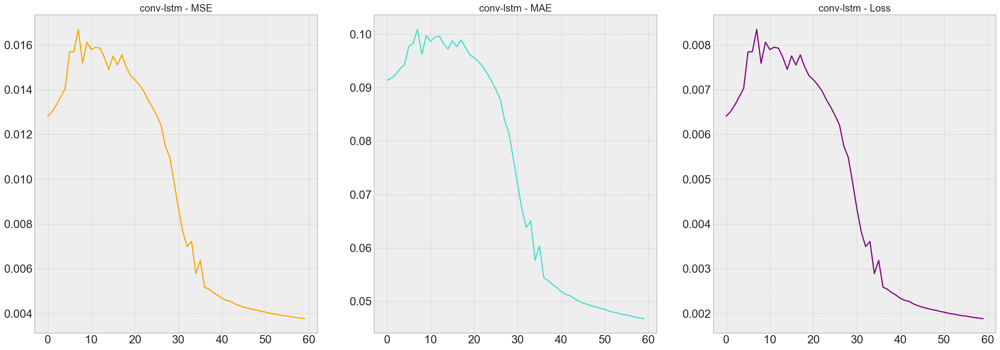

In [173]:
cldhistory,cldm=model_fits(cld,'conv-lstm',1e-5,60) 

14/14 [==============================] - 2s 53ms/step


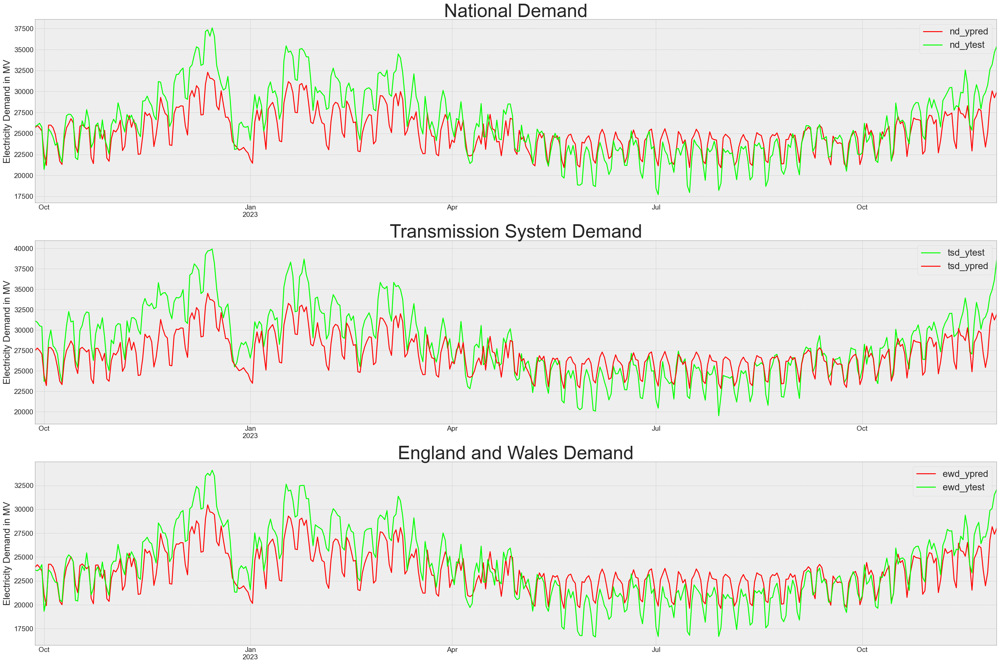

In [174]:
cld=tf.keras.models.load_model("C:/Users/Sethu/Downloads/save besgt/savebestonlymodel.h5")
cldframe,cld_metrics=predict_withplot(cld,xtest_combined) 

In [175]:
cld_metrics

,National Demand,Transmission System Demand,England and Wales Demand
Mean Squared Error,6354857.0,7792289.0,4476493.0
Squared Root (mse),2521.0,2791.0,2116.0
Mean Absolute Error,2011.0,2276.0,1753.0
Mean Absolute Percentage Error,0.0,0.0,0.0


In [168]:
cldforecast=forecasts(cld,366)

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 22ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 23ms

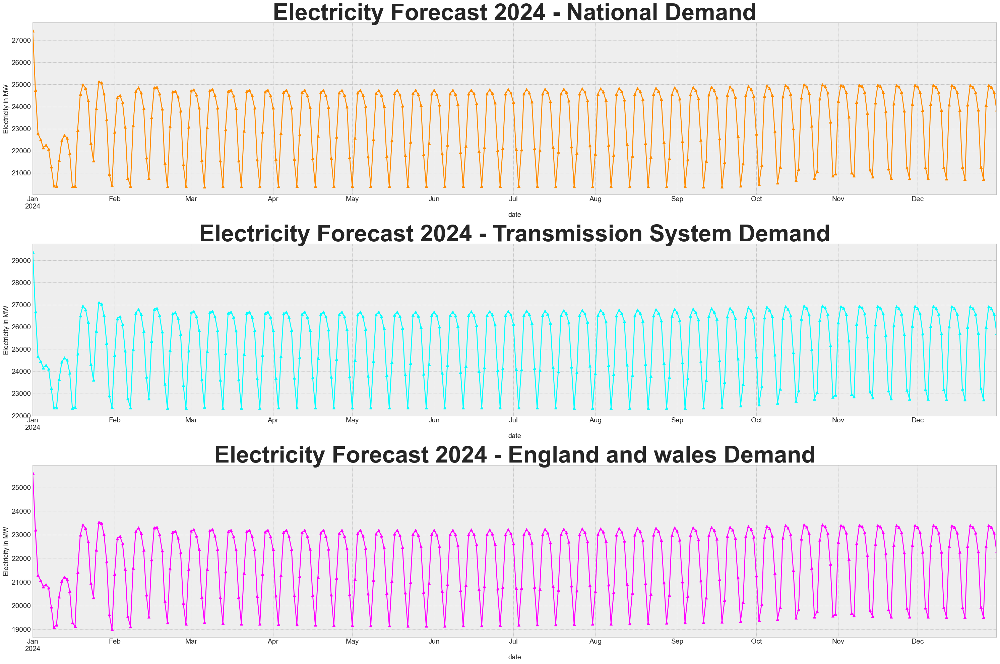

In [169]:
f_2024(cldforecast)

# B) CONVOLUTION + GRU + DNN MODEL

In [182]:

cgd=tf.keras.Sequential([Conv1D(filters=32,kernel_size=3,strides=1,padding='causal',activation='relu',
                               input_shape=(xtrain_combined.shape[1], xtrain_combined.shape[2])),
                         
                         Conv1D(filters=64,kernel_size=3,strides=1,padding='causal',activation='relu'),
                         
                         Conv1D(filters=128,kernel_size=3,padding='causal',activation='relu'),
                         
                         MaxPooling1D(pool_size=2,strides=1,padding='same'),
                         
                         Bidirectional(GRU(units=120,activation='relu',return_sequences=True)),
                         
                         Bidirectional(GRU(units=120,activation='relu',return_sequences=True)),
                         
                         Bidirectional(GRU(units=120,activation='relu',return_sequences=True)),
                         
                         Bidirectional(GRU(units=100,activation='relu',return_sequences=True)),
                         
                         LSTM(units=100,activation='relu',return_sequences=False),
                         
                         Dense(units=84,activation='relu'),
                         
                         Dense(units=77,activation='relu'),
                         
                         Dense(units=44,activation='relu'),
                         
                         Dense(units=22,activation='relu'),
                         
                         Dense(units=9,activation='relu'),
                         
                         Dense(units=num_features, activation='linear', name=f'Final_layer_with_{num_features}_output')   
])

In [183]:
cgd.summary()

Model: "sequential_24"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 conv1d_31 (Conv1D)          (None, 12, 32)            320       

                                                                 

 conv1d_32 (Conv1D)          (None, 12, 64)            6208      

                                                                 

 conv1d_33 (Conv1D)          (None, 12, 128)           24704     

                                                                 

 max_pooling1d_11 (MaxPooli  (None, 12, 128)           0         

 ng1D)                                                           

                                                                 

 bidirectional_40 (Bidirect  (None, 12, 240)           180000    

 ional)                                                          

                                                                 

 bidirectional_41 (Bidirect  (None, 1

Epoch 1/100

200/200 [==============================] - 11s 20ms/step - loss: 0.0138 - lr: 1.0000e-09

Epoch 2/100

200/200 [==============================] - 4s 21ms/step - loss: 0.0136 - lr: 1.1220e-09

Epoch 3/100

200/200 [==============================] - 4s 21ms/step - loss: 0.0045 - lr: 1.2589e-09

Epoch 4/100

200/200 [==============================] - 4s 22ms/step - loss: 0.0123 - lr: 1.4125e-09

Epoch 5/100

200/200 [==============================] - 4s 22ms/step - loss: 0.0016 - lr: 1.5849e-09

Epoch 6/100

200/200 [==============================] - 4s 22ms/step - loss: 0.0106 - lr: 1.7783e-09

Epoch 7/100

200/200 [==============================] - 5s 24ms/step - loss: 0.0019 - lr: 1.9953e-09

Epoch 8/100

200/200 [==============================] - 5s 23ms/step - loss: 0.0085 - lr: 2.2387e-09

Epoch 9/100

200/200 [==============================] - 5s 24ms/step - loss: 0.0120 - lr: 2.5119e-09

Epoch 10/100

200/200 [==============================] - 5s 24ms/step - loss: 0.0

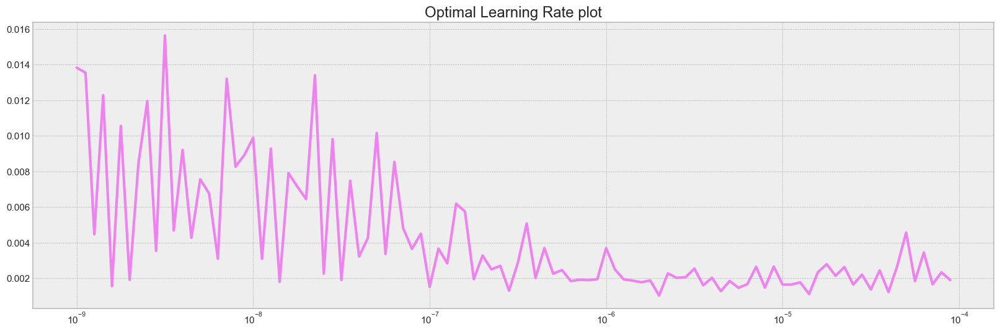

In [189]:
lr_(cgd,100)

Epoch 1/100

1718/1718 [==============================] - ETA: 0s - loss: 0.0623 - mse: 0.1245 - mae: 0.2638

Epoch 1: mae improved from inf to 0.26383, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 100s 52ms/step - loss: 0.0623 - mse: 0.1245 - mae: 0.2638

Epoch 2/100

1718/1718 [==============================] - ETA: 0s - loss: 0.0076 - mse: 0.0153 - mae: 0.0987

Epoch 2: mae improved from 0.26383 to 0.09871, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 81s 47ms/step - loss: 0.0076 - mse: 0.0153 - mae: 0.0987

Epoch 3/100

1718/1718 [==============================] - ETA: 0s - loss: 0.0069 - mse: 0.0139 - mae: 0.0947

Epoch 3: mae improved from 0.09871 to 0.09466, saving model to C:/Users/Sethu/Downloads/save besgt\savebestonlymodel.h5

1718/1718 [==============================] - 95s 55ms/step - loss: 0.0069 - mse: 0.0139 - mae: 0.0947

E

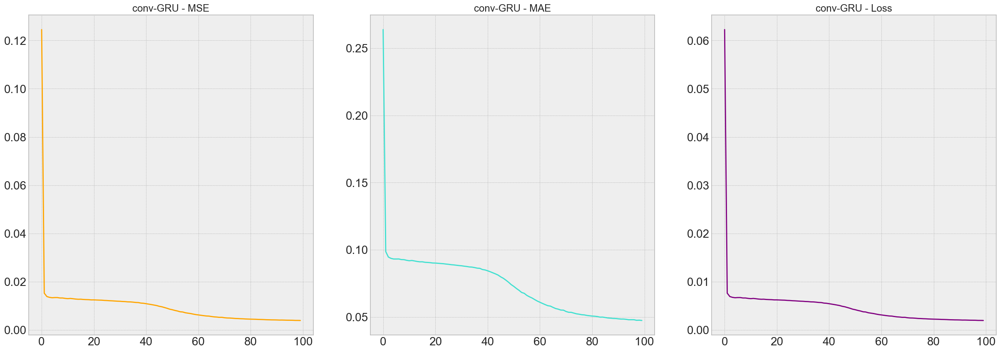

In [184]:
cgdhistory,cgdm=model_fits(cgd,'conv-GRU',1e-4,100) 

14/14 [==============================] - 2s 23ms/step


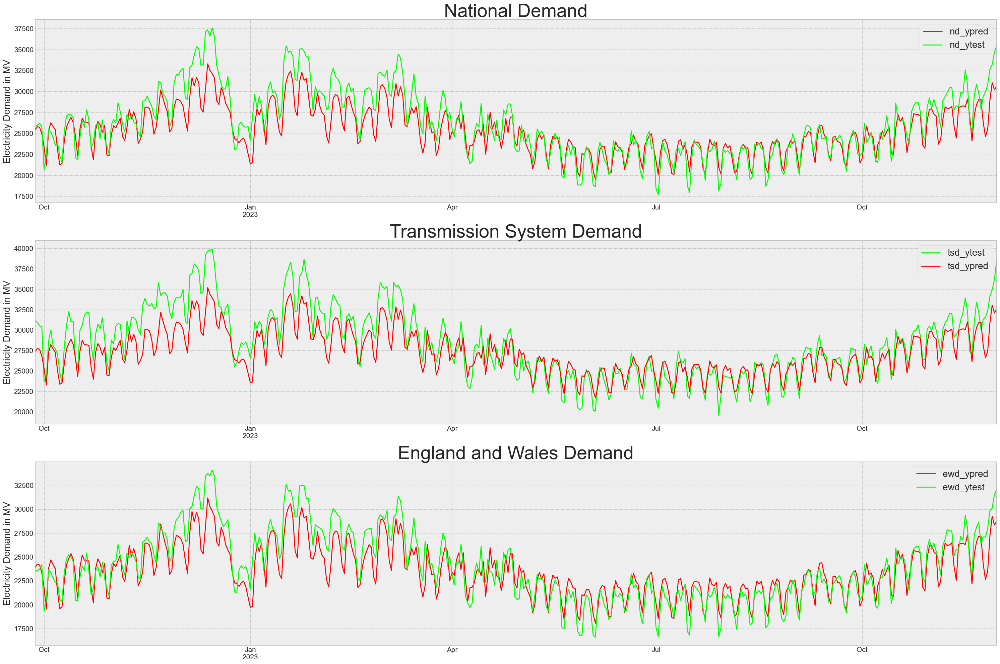

In [185]:
cgd=tf.keras.models.load_model("C:/Users/Sethu/Downloads/save besgt/savebestonlymodel.h5")
cgdframe,cgd_metrics=predict_withplot(cgd,xtest_combined) 

In [186]:
cgd_metrics

,National Demand,Transmission System Demand,England and Wales Demand
Mean Squared Error,4141452.0,5372836.0,3028493.0
Squared Root (mse),2035.0,2318.0,1740.0
Mean Absolute Error,1563.0,1823.0,1369.0
Mean Absolute Percentage Error,0.0,0.0,0.0


In [187]:
cgdforecast=forecasts(cgd,366)

1/1 [==============================] - 0s 34ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 30ms/step

1/1 [==============================] - 0s 27ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 27ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 30ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 23ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 25ms/step

1/1 [==============================] - 0s 26ms/step

1/1 [==============================] - 0s 24ms/step

1/1 [==============================] - 0s 25ms

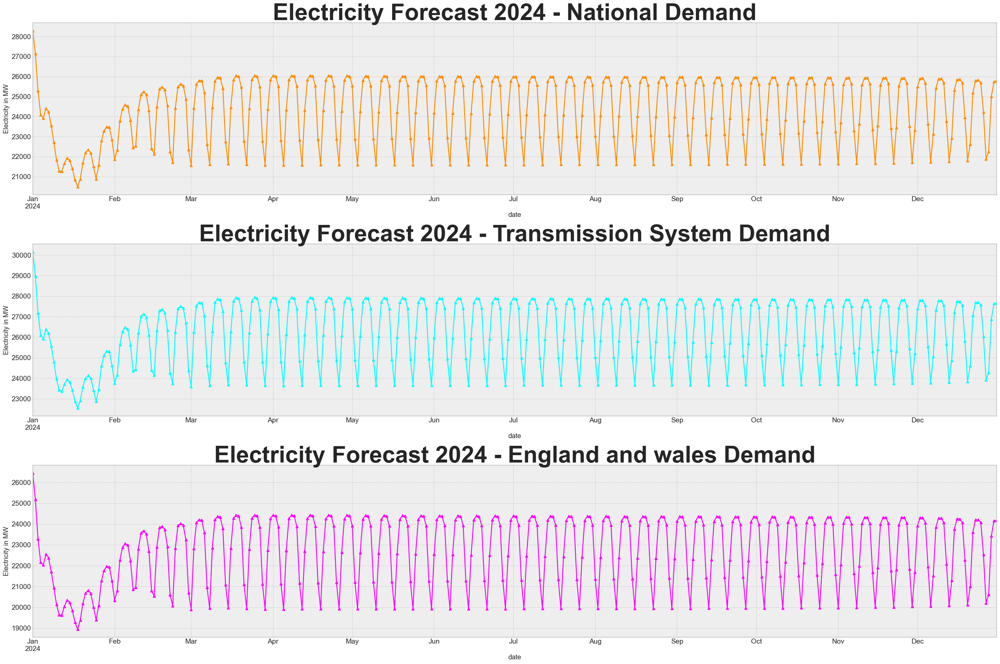

In [188]:
f_2024(cgdforecast)

# Thank You!

@ Refrences:

1) https://www.kaggle.com/code/vaibhavsxn/time-series-multivariate-lstm

2) https://www.analyticsvidhya.com/blog/2020/10/multivariate-multi-step-time-series-forecasting-using-stacked-lstm-sequence-to-sequence-autoencoder-in-tensorflow-2-0-keras/

3) https://machinelearningmastery.com/how-to-use-the-timeseriesgenerator-for-time-series-forecasting-in-keras/

4) https://www.geeksforgeeks.org/gated-recurrent-unit-networks/

5) https://deepai.org/machine-learning-glossary-and-terms/gated-neural-network

6) https://www.geeksforgeeks.org/time-series-forecasting-using-recurrent-neural-networks-rnn-in-tensorflow/

7) https://www.kaggle.com/code/fatmakursun/time-series-forecasting-unknown-future

# **KINDLY UPVOTE THE NOTEBOOK IF YOU FIND IT INSIGHTFUL**